# Water-cycle response to afforestation — concluding analysis (Pr, SM) — `_simple` variant

**This is the `_simple` companion to `water_avail_final.ipynb`.** Everything is identical --
same data loading, same Section 1 (LAI-sensitivity regression, treeFrac-ratio barplots), same
growing-season/regime masking -- **except that Section 2's spatial-shift permutation null test
has been removed**, at explicit request: afforestation location in these LUMIP runs is set by
the IAM's land-use trajectory (`ssp126Lu`), not placed at a random longitude, so a null built on
"would this effect appear if the class geometry were placed anywhere in longitude" was answering
a question about scenario geometries that were never actually on the table. What matters here is
whether afforestation, at the locations the scenario actually puts it, differs significantly from
non-afforested land -- treating the class assignment as fixed rather than testing it against a
random-placement counterfactual. See Section 2's intro cell (`## \`_simple\`: no spatial-shift
permutation test, by explicit request`) for exactly what changed and what's used instead.
Figures/CSVs are written with `FIG_PREFIX = "dist_simple_"` instead of `"dist_"`, so running both
notebooks against the same `out_path` doesn't overwrite either output.

**This is the paper's concluding biophysical-impact analysis**: the effect of afforestation
(ssp126Lu, "aff") vs. the control (ssp370, "ctl") on precipitation (`pr`) and depth-weighted
root-zone soil moisture (`mrsol`), across the 7-model LUMIP ensemble. It merges two source
notebooks, each revised in place for the two repository-wide bug fixes documented in
`lumip_utils.py`: the corrected 4GST evergreen test, and the evaporative-regime
classification (`regime_limit`/`classify_regime`), which now defaults to `method="raw"`
(non-deseasonalized, matching the pre-revision notebooks) per the user's explicit follow-up
request -- `method="deseason"` remains available and is the statistically more defensible
choice; see `lumip_utils.py` / `REVISION_NOTES.md`:

1. **Section 1 — `water_avail_gs.ipynb`** (cells 0-36 of the original only). This is the
   growing-season LAI-sensitivity regression and the end-of-century
   `Delta(Pr,SM) / Delta(treeFrac)` ratio analysis, ending in the two figures the paper's
   conclusion is built on: `dPr_dTreeFrac_30yr_barplot` and `dSM_dTreeFrac_30yr_barplot`.
   **The original notebook's `# OLD` section (its cell 37 onward — a superseded spatial/zonal
   water-availability analysis) is dropped entirely**, per explicit instruction; it played no
   role in the paper's current conclusions.
2. **Section 2 — `water_avail_distributions.ipynb`**, simplified. A self-contained companion:
   multi-model-mean distributions of dPr/dSM by land-cover class and evaporative regime, using
   Cliff's delta, the Hodges-Lehmann shift, and a block-bootstrap CI as the precision/significance
   indicator (no spatial-shift permutation -- see above). It answers a narrower, descriptive
   question than Section 1 and is included as supporting evidence, not a replacement.

Both sections load their own data independently under the same variable names
(`xr_aff`, `xr_ctl`, `models`, `data_path`, ...); Section 2's cells do not depend on any
Section-1 state, so running the whole notebook top-to-bottom reproduces both source notebooks'
original behaviour (module state included) except for the two bug fixes and the Section-2
simplification described above.

# Section 1 -- LAI-sensitivity regression and end-of-century treeFrac-ratio analysis (from `water_avail_gs.ipynb`)

In [1]:
import os
import glob

import math
import matplotlib as mpl
import matplotlib.colors as colors
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cartopy as cart
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.mpl.ticker as cticker
from cartopy.util import add_cyclic_point
import seaborn as sns

import numpy as np
import xarray as xr
import cftime
import pandas as pd


In [2]:
work = "locale_mc" # or "levante"

if work == "levante":
    data_path = "/home/m/m301093/data/clean/"
    out_path = "/home/m/m301093/results_biophys/"
if work == "locale_wnd":
    data_path = "G:/My Drive/MPIM/data/"
    out_path = "G:/My Drive/MPIM/Figures/"
if work == "locale_mc":
    data_path = "/Users/matteomastropierro/Documents/afforestation_LUMIP/data/"
    out_path = "/Users/matteomastropierro/Documents/afforestation_LUMIP/Submission/" \
    "Figures/"

## Functions

In [3]:
def xr_multimodel_sign(xr_in, models):
    # Computes the Multimodel MEAN and STD
    # xr_in: list of xarray models
    mm = xr.concat(xr_in, dim = "esm", coords = "minimal", compat = "override")
    
    std = xr.concat(xr_in, dim = "esm", coords = "minimal", compat = "override").std(dim = "esm")
    
    # Multimodel agreement in the sign of the sensitivity
    sign = xr.where(mm > 0, 1, -1)
    agreement = (np.abs(sign.sum(dim = "esm")/len(models)))
    
    mean = mm.mean(dim = "esm")
    return (mean, std, agreement)

def cell_weight(ds):
    R = 6.371e6
    dϕ = np.deg2rad(ds.lat[1] - ds.lat[0])
    dλ = np.deg2rad(ds.lon[1] - ds.lon[0])
    dlat = R * dϕ * xr.ones_like(ds.lon)
    dlon = R * dλ * np.cos(np.deg2rad(ds.lat))
    cell_area = dlon * dlat
    return(cell_area)

def apply_rolling_mean(ds, window=2, dim="time"):
    # Create a new dataset to store the results
    rolled_ds = xr.Dataset()
    
    for var in ds.data_vars:
        print(f"Processing variable: {var}")
        
        try:
            # Apply rolling mean and dropna to each variable
            rolled_var = ds[var].rolling({dim: window}, center = "left").mean().dropna(dim)
            
            # Add the rolled variable to the new dataset
            rolled_ds[var] = rolled_var
        except Exception as e:
            print(f"Error processing variable {var}: {e}")
        
    return rolled_ds

def detrend_dim(da, dim, degree):
    # detrend along a single dimension
    p = da.polyfit(dim=dim, deg=degree)
    fit = xr.polyval(da[dim], p.polyfit_coefficients)
    da_det = (da - fit)
    return da_det

In [4]:
#### --------- Mann-Whitney Test --------- ####
from scipy.stats import mannwhitneyu

# Test applied on a grid-cell basis. For every gid-cell, the statistical difference between two time series is computed.
# 1st time series: Nino years' (DS_models_hist_nino)
# 2nd time series: Reference climatology (DS_models_hist_clim or DS_models_hist_clim_neutral)  

## -- Function for grid-cell operations -- ##
def multi_apply_along_axis(func1d, axis, arrs, *args, **kwargs):
    """
    Given a function `func1d(A, B, C, ..., *args, **kwargs)`  that acts on 
    multiple one dimensional arrays, apply that function to the N-dimensional
    arrays listed by `arrs` along axis `axis`
    
    If `arrs` are one dimensional this is equivalent to::
    
        func1d(*arrs, *args, **kwargs)
    
    If there is only one array in `arrs` this is equivalent to::
    
        numpy.apply_along_axis(func1d, axis, arrs[0], *args, **kwargs)
        
    All arrays in `arrs` must have compatible dimensions to be able to run
    `numpy.concatenate(arrs, axis)`
    
    Arguments:
        func1d:   Function that operates on `len(arrs)` 1 dimensional arrays,
                  with signature `f(*arrs, *args, **kwargs)`
        axis:     Axis of all `arrs` to apply the function along
        arrs:     Iterable of numpy arrays
        *args:    Passed to func1d after array arguments
        **kwargs: Passed to func1d as keyword arguments
    """
    # Concatenate the input arrays along the calculation axis to make one big
    # array that can be passed in to `apply_along_axis`
    carrs = np.concatenate(arrs, axis)
    
    # We'll need to split the concatenated arrays up before we apply `func1d`,
    # here's the offsets to split them back into the originals
    offsets=[]
    start=0
    for i in range(len(arrs)-1):
        start += arrs[i].shape[axis]
        offsets.append(start)
            
    # The helper closure splits up the concatenated array back into the components of `arrs`
    # and then runs `func1d` on them
    def helperfunc(a, *args, **kwargs):
        arrs = np.split(a, offsets)
        return func1d(*[*arrs, *args], **kwargs)
    
    # Run `apply_along_axis` along the concatenated array
    return np.apply_along_axis(helperfunc, axis, carrs, *args, **kwargs)


def xr_multipletest(p, alpha=0.05, method='fdr_bh', **multipletests_kwargs):
    """Apply statsmodels.stats.multitest.multipletests for multi-dimensional xr.objects."""
    from statsmodels.stats.multitest import multipletests
    # stack all to 1d array
    p_stacked = p.stack(s=p.dims)
    # mask only where not nan: https://github.com/statsmodels/statsmodels/issues/2899
    mask = np.isfinite(p_stacked)
    pvals_corrected = np.full(p_stacked.shape, np.nan)
    reject = np.full(p_stacked.shape, np.nan)
    # apply test where mask
    reject[mask] = multipletests(
        p_stacked[mask], alpha=alpha, method=method, **multipletests_kwargs)[0]
    pvals_corrected[mask] = multipletests(
        p_stacked[mask], alpha=alpha, method=method, **multipletests_kwargs)[1]

    def unstack(reject, p_stacked):
        """Exchange values from p_stacked with reject (1d array) and unstack."""
        xreject = p_stacked.copy()
        xreject.values = reject
        xreject = xreject.unstack()
        return xreject

    reject = unstack(reject, p_stacked)
    pvals_corrected = unstack(pvals_corrected, p_stacked)
    return reject, pvals_corrected


In [5]:
def lag_linregress_3D(x, y, lagx=0, lagy=0):
    """
    Input: Two xr.Datarrays of any dimensions with the first dim being time. 
    Thus the input data could be a 1D time series, or for example, have three dimensions (time,lat,lon). 
    Datasets can be provied in any order, but note that the regression slope and intercept will be calculated
    for y with respect to x.
    Output: Covariance, correlation, regression slope and intercept, p-value, and standard error on regression
    between the two datasets along their aligned time dimension.  
    Lag values can be assigned to either of the data, with lagx shifting x, and lagy shifting y, with the specified lag amount. 
    """ 
    #1. Ensure that the data are properly alinged to each other. 
    x,y = xr.align(x,y)
    
    #2. Add lag information if any, and shift the data accordingly
    if lagx!=0:
        #If x lags y by 1, x must be shifted 1 step backwards. 
        #But as the 'zero-th' value is nonexistant, xr assigns it as invalid (nan). Hence it needs to be dropped
        x   = x.shift(time = -lagx).dropna(dim='time')
        #Next important step is to re-align the two datasets so that y adjusts to the changed coordinates of x
        x,y = xr.align(x,y)

    if lagy!=0:
        y   = y.shift(time = -lagy).dropna(dim='time')
        x,y = xr.align(x,y)
 
    #3. Compute data length, mean and standard deviation along time axis for further use: 
    n     = x.shape[0]
    xmean = x.mean(axis=0)
    ymean = y.mean(axis=0)
    xstd  = x.std(axis=0)
    ystd  = y.std(axis=0)
    
    #4. Compute covariance along time axis
    cov   =  np.sum((x - xmean)*(y - ymean), axis=0)/(n)
    
    #5. Compute correlation along time axis
    cor   = cov/(xstd*ystd)
    
    #6. Compute regression slope and intercept:
    slope     = cov/(xstd**2)
    intercept = ymean - xmean*slope
    y_pred =  intercept + slope*x
    res = y - y_pred

    #7. Compute P-value and standard error
    #Compute t-statistics
    tstats = cor*np.sqrt(n-2)/np.sqrt(1-cor**2)
    stderr = slope/tstats
    
    from scipy.stats import t
    pval   = t.sf(tstats, n-2)*2
    pval   = xr.DataArray(pval, dims=cor.dims, coords=cor.coords)

    #return cov,cor,slope,intercept,pval,stderr
    results = {}
    results["cor"] = cor
    results["coef"] = slope
    results["pval"] = pval
    return results

## Import preprocessed data

In [6]:
models = [ "ACCESS-ESM1-5", "CMCC-ESM2", "CESM2", "CanESM5", "IPSL-CM6A-LR", "MPI-ESM1-2-LR", "UKESM1-0-LL"]

In [7]:
scenario = 'ssp126Lu'
xr_aff = []
for i,mm in enumerate(models):
    filepath = glob.glob(os.path.join(data_path + 'xr_' + scenario + "_" + mm + '.nc'))[0]                                       ## List of files sorted by name
    content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
    xr_aff.append(content)


scenario = 'ssp370'
xr_ctl = []
for i,mm in enumerate(models):
    filepath = glob.glob(os.path.join(data_path + 'xr_' + scenario + "_" + mm + '.nc'))[0]                                       ## List of files sorted by name
    content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
    xr_ctl.append(content)


/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_3756/617599065.py:5: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 240. This could degrade performance. Instead, consider rechunking after loading.
  content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_3756/617599065.py:5: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 240. This could degrade performance. Instead, consider rechunking after loading.
  content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_3756/617599065.py:5: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 240. This could degrade performa

In [8]:
scenario = 'ssp126Lu'
xr_aff_pft = []
for i,mm in enumerate(models):
    filepath = glob.glob(os.path.join(data_path + 'xr_' + scenario + "_" + mm + '_pft.nc'))[0]                                       ## List of files sorted by name
    content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
    xr_aff_pft.append(content)


scenario = 'ssp370'
xr_ctl_pft = []
for i,mm in enumerate(models):
    filepath = glob.glob(os.path.join(data_path + 'xr_' + scenario + "_" + mm + '_pft.nc'))[0]                                       ## List of files sorted by name
    content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
    xr_ctl_pft.append(content)


/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_3756/1516825723.py:5: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 240. This could degrade performance. Instead, consider rechunking after loading.
  content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_3756/1516825723.py:5: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 240. This could degrade performance. Instead, consider rechunking after loading.
  content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_3756/1516825723.py:5: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 240. This could degrade perfo

### Preprocessing

In [9]:
# CanESM5 does not provide Latent Heat
# We derive it as Rn - H (ignoring Ground Heat fluxes that are negligible over land)

xr_ctl[3]["hfls"] = (xr_ctl[3].rsds - xr_ctl[3].rlds) - xr_ctl[3].hfss
xr_aff[3]["hfls"] = (xr_aff[3].rsds - xr_aff[3].rlds) - xr_aff[3].hfss

# Rename ta to tas 
xr_aff[3] = xr_aff[3].rename({"ta":"tas"})
xr_ctl[3] = xr_ctl[3].rename({"ta":"tas"})

# Select the first pressure level
xr_aff[3] = xr_aff[3].isel(plev = 0)
xr_ctl[3] = xr_ctl[3].isel(plev = 0)

# Try to interpolate surface temperature for CanESM5
xr_ctl[3]["tas"] = (xr_ctl[3].ts + xr_ctl[3].tas)/2
xr_aff[3]["tas"] = (xr_aff[3].ts + xr_aff[3].tas)/2


In [10]:
# Convert pr and evspsbl from kg m-2 s-1 to mm month-1
for i,mm in enumerate(models):
    xr_ctl[i]["pr"] = xr_ctl[i].pr*86400* xr_ctl[i].time.dt.days_in_month
    xr_aff[i]["pr"] = xr_aff[i].pr*86400* xr_aff[i].time.dt.days_in_month
    
    xr_ctl[i]["pr"].attrs=dict(units="mm/months")
    xr_aff[i]["pr"].attrs=dict(units="mm/months")

    if mm == "CMCC-ESM2" or "CESM2": # LE in W*m^2; λ is in MJ kg-1 = MW*s kg-1 
        # https://earthscience.stackexchange.com/questions/20733/fluxnet15-how-to-convert-latent-heat-flux-to-actual-evapotranspiration
        xr_ctl[i]["evspsbl"] = xr_ctl[i].hfls/(2.501 - (2.361e-3) * (xr_ctl[i].tas-273.15))*10**6
        xr_aff[i]["evspsbl"] = xr_aff[i].hfls/(2.501 - (2.361e-3) * (xr_aff[i].tas-273.15))*10**6
    else:
        None
        
    xr_ctl[i]["evspsbl"] = xr_ctl[i].evspsbl*86400* xr_ctl[i].time.dt.days_in_month
    xr_aff[i]["evspsbl"] = xr_aff[i].evspsbl*86400* xr_aff[i].time.dt.days_in_month
    
    xr_ctl[i]["evspsbl"].attrs=dict(units="mm/months")
    xr_aff[i]["evspsbl"].attrs=dict(units="mm/months")

In [11]:
# Homogenize lat and lon
for i,mm in enumerate(models):
    content = xr_aff[i]
    xr_aff_pft[i]["lat"] = content.tas.lat; xr_aff_pft[i]["lon"] = content.lon

    content = xr_ctl[i]
    xr_ctl_pft[i]["lat"] = content.tas.lat; xr_ctl_pft[i]["lon"] = content.lon

### Soil Moisture

In [12]:
%%capture

scenario = 'ssp370-ssp126Lu'
xr_aff_mrsol = []
for i,mm in enumerate(models):
    filepath = glob.glob(os.path.join(data_path + 'mrsol_*_' + mm + "_" + scenario + "_" + '*.nc'))[0]
    content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
    xr_aff_mrsol.append(content)


scenario = 'ssp370'
xr_ctl_mrsol = []
for i,mm in enumerate(models):
    filepath = glob.glob(os.path.join(data_path + 'mrsol_*_' + mm + "_" + scenario + "_"  + '*.nc'))[0]
    content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
    xr_ctl_mrsol.append(content)

# Rename IPSL height dimension
xr_aff_mrsol[4] = xr_aff_mrsol[4].rename({"solay": "depth"})
xr_ctl_mrsol[4] = xr_ctl_mrsol[4].rename({"solay": "depth"})

# All 7 models are included in the soil-moisture sensitivity analysis.
models_mrsol = list(models)

# IPSL-CM6A-LR's raw mrsol file carries no depth_bnds -- its "depth" (renamed from "solay")
# is a bare model-level index (1..11), not a physical depth coordinate. Per the ORCHIDEE
# hydrology grid used in IPSL-CM6A-LR, these 11 levels span a total soil column of 2 m; we
# therefore treat them as 11 layers of uniform thickness 2/11 m (no finer per-layer geometry
# is available for this model).
IPSL_TOTAL_DEPTH = 2.0   # m, full hydrological column


def xr_fix_time(xr_in, date_start, date_end):

    if xr_in['time'].dt.calendar == 'noleap' or xr_in['time'].dt.calendar == '360_day':
        xr_in = xr_in.convert_calendar(calendar = 'gregorian', align_on = 'date')

    else: None

    time = pd.date_range(start=date_start, end=date_end, freq='ME').to_numpy(dtype='datetime64[ns]')
    xr_out = xr_in.assign_coords(time = time)

    return xr_out
def xr_clean(xr_in, dims):
    data = xr_in.copy()
    for i,d in enumerate(dims):
        if d in data.coords and d in data.dims:
            data = data.drop(d)
            data = data.isel({d : 0})
        if d in data.coords:
            data = data.drop(d)
        if d in data.dims and d not in data.coords:
            data = data.isel({d : 0})
        if data.attrs == {}:
            None
        else:
            if d in data.data_vars:
                data = data.drop_vars(d)
    xr_out = data
    return xr_out
def lon180(ds):
    ds.coords['lon'] = (ds.coords['lon'] + 180) % 360 - 180
    ds = ds.sortby(ds.lon)
    return ds


DEPTH_RANGE = (0, 2)   # root-zone soil column considered, in metres (depth-label bounds)
RHO_W = 1000.0         # water density, kg m-3

for i,item in enumerate(models):
    xr_aff_mrsol[i] = xr_aff_mrsol[i].sel(lat=slice(-60,90))
    xr_ctl_mrsol[i] = xr_ctl_mrsol[i].sel(lat=slice(-60,90))

    is_ipsl = (item == "IPSL-CM6A-LR")

    if not is_ipsl:
        # Layer thickness (m) must be extracted from depth_bnds BEFORE xr_clean(), which
        # collapses the "bnds" dimension via .isel(bnds=0) and would otherwise discard the
        # upper bound of every layer, making the thickness uncomputable afterwards.
        dz_aff = xr_aff_mrsol[i]["depth_bnds"].sel(depth=slice(*DEPTH_RANGE)).diff("bnds").squeeze("bnds")
        dz_ctl = xr_ctl_mrsol[i]["depth_bnds"].sel(depth=slice(*DEPTH_RANGE)).diff("bnds").squeeze("bnds")
        total_depth_aff = float(dz_aff.sum("depth"))
        total_depth_ctl = float(dz_ctl.sum("depth"))
    else:
        # No depth_bnds available; use the documented 2 m ORCHIDEE column depth instead.
        total_depth_aff = IPSL_TOTAL_DEPTH
        total_depth_ctl = IPSL_TOTAL_DEPTH

    xr_aff_mrsol[i] = xr_clean(xr_aff_mrsol[i], ['dcpp_init_year', 'member_id', 'lon_bnds', 'lat_bnds', 'time_bnds', 'bnds'])
    xr_ctl_mrsol[i] = xr_clean(xr_ctl_mrsol[i], ['dcpp_init_year', 'member_id', 'lon_bnds', 'lat_bnds', 'time_bnds', 'bnds'])

    xr_aff_mrsol[i] = lon180(xr_aff_mrsol[i])
    xr_ctl_mrsol[i] = lon180(xr_ctl_mrsol[i])

    xr_aff_mrsol[i] = xr_fix_time(xr_aff_mrsol[i],"2015-01","2101-01")
    xr_ctl_mrsol[i] = xr_fix_time(xr_ctl_mrsol[i],"2015-01","2101-01")

    # kg m-2 (mass content per layer) -> m3 m-3 (volumetric water content), as a
    # thickness-weighted mean over the selected root-zone layers.
    # NOTE: dividing by RHO_W alone (as in an earlier version) returns an equivalent water
    # DEPTH in metres for the summed layers, not a volumetric fraction. Dividing by
    # (RHO_W * total_depth) gives the actual dimensionless m3 m-3 quantity.
    if not is_ipsl:
        xr_aff_mrsol[i] = (xr_aff_mrsol[i].sel(depth=slice(*DEPTH_RANGE))["mrsol"].sum(dim = "depth")
                           / (RHO_W * total_depth_aff))
        xr_ctl_mrsol[i] = (xr_ctl_mrsol[i].sel(depth=slice(*DEPTH_RANGE))["mrsol"].sum(dim = "depth")
                           / (RHO_W * total_depth_ctl))
    else:
        # IPSL's 11 "depth" levels are a bare index (1..11), not a physical coordinate, so
        # depth=slice(0,2) would wrongly select only levels 1-2. We sum over all 11 levels,
        # which by the ORCHIDEE grid span the full 0-2 m column (see IPSL_TOTAL_DEPTH above).
        xr_aff_mrsol[i] = xr_aff_mrsol[i]["mrsol"].sum(dim = "depth") / (RHO_W * total_depth_aff)
        xr_ctl_mrsol[i] = xr_ctl_mrsol[i]["mrsol"].sum(dim = "depth") / (RHO_W * total_depth_ctl)

    xr_aff_mrsol[i] = xr_aff_mrsol[i].assign_attrs(units = "m3 m-3")
    xr_ctl_mrsol[i] = xr_ctl_mrsol[i].assign_attrs(units = "m3 m-3")

    # Homogenize lat and lon
    xr_aff_mrsol[i]["lat"] = xr_aff[i].lat; xr_aff_mrsol[i]["lon"] = xr_aff[i].lon
    xr_ctl_mrsol[i]["lat"] = xr_aff[i].lat; xr_ctl_mrsol[i]["lon"] = xr_aff[i].lon

    xr_aff[i] = xr.merge([xr_aff[i], xr_aff_mrsol[i].rename("mrsol").to_dataset()])
    xr_ctl[i] = xr.merge([xr_ctl[i], xr_ctl_mrsol[i].rename("mrsol").to_dataset()])


### Transpiration

In [13]:
%%capture

models_tran = ["CMCC-ESM2", "CESM2", "CanESM5", "IPSL-CM6A-LR", "UKESM1-0-LL"]

scenario = 'ssp370-ssp126Lu'
xr_aff_tran = {}
for i,mm in enumerate(models_tran):
    filepath = glob.glob(os.path.join(data_path + 'tran_*_' + mm +'_'+ scenario + "_" + '*.nc'))[0]                                       ## List of files sorted by name
    content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
    xr_aff_tran[mm] = content

scenario = 'ssp370'
xr_ctl_tran = {}
for i,mm in enumerate(models_tran):
    filepath = glob.glob(os.path.join(data_path + 'tran_*_' + mm +'_'+ scenario + "_"  + '*.nc'))[0]                                       ## List of files sorted by name
    content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
    xr_ctl_tran[mm] = content
    
for i,mm in enumerate(models_tran):
    xr_aff_tran[mm] = xr_aff_tran[mm].sel(lat=slice(-60,90))
    xr_ctl_tran[mm] = xr_ctl_tran[mm].sel(lat=slice(-60,90))
    
    xr_aff_tran[mm] = xr_clean(xr_aff_tran[mm], ['dcpp_init_year', 'member_id', 'lon_bnds', 'lat_bnds', 'time_bnds', 'bnds'])
    xr_ctl_tran[mm] = xr_clean(xr_ctl_tran[mm], ['dcpp_init_year', 'member_id', 'lon_bnds', 'lat_bnds', 'time_bnds', 'bnds'])

    xr_aff_tran[mm] = lon180(xr_aff_tran[mm])
    xr_ctl_tran[mm] = lon180(xr_ctl_tran[mm])

    xr_aff_tran[mm] = xr_fix_time(xr_aff_tran[mm],"2015-01","2101-01")
    xr_ctl_tran[mm] = xr_fix_time(xr_ctl_tran[mm],"2015-01","2101-01")

    xr_aff_tran[mm] = xr_aff_tran[mm].tran*86400* xr_aff_tran[mm].time.dt.days_in_month
    xr_ctl_tran[mm] = xr_ctl_tran[mm].tran*86400* xr_ctl_tran[mm].time.dt.days_in_month
    
    xr_aff_tran[mm].attrs=dict(units="mm/months")
    xr_ctl_tran[mm].attrs=dict(units="mm/months")
    xr_ctl_tran[mm] = xr_ctl_tran[mm].rename("tran").to_dataset()
    xr_aff_tran[mm] = xr_aff_tran[mm].rename("tran").to_dataset()

## Afforestation and regime masking

In [14]:
xr_delta = []
xr_delta_pft = []
for i,mm in enumerate(models):
    xr_delta.append(xr_aff[i].sel(time = slice("2071-01","2100-12")).mean(dim = "time") - xr_ctl[i].sel(time = slice("2071-01","2100-12")).mean(dim = "time"))
    xr_delta_pft.append(xr_aff_pft[i].sel(time = slice("2071-01","2100-12")).mean(dim = "time") - xr_ctl_pft[i].sel(time = slice("2071-01","2100-12")).mean(dim = "time"))

In [15]:
%%capture

# masking regions of treefrac increase or decrease
mask_treefrac_pos = []
mask_treefrac_neg = []

for m,_ in enumerate(models):
    # identify regions with 5%+ and 5%- treefrac
    mask_treefrac_pos.append(xr_delta_pft[m]["treeFrac"].where(xr_delta_pft[m]["treeFrac"] > 10))
    mask_treefrac_neg.append(xr_delta_pft[m]["treeFrac"].where(xr_delta_pft[m]["treeFrac"] <- 10))


for i,item in enumerate(models):
    # Homogenize lat and lon
    xr_aff_mrsol[i]["lat"] = mask_treefrac_pos[i].lat; xr_aff_mrsol[i]["lon"] = mask_treefrac_pos[i].lon
    xr_ctl_mrsol[i]["lat"] = mask_treefrac_pos[i].lat; xr_ctl_mrsol[i]["lon"] = mask_treefrac_pos[i].lon

In [16]:
# FIX 1 (Bug 1) -- evaporative-regime classification, now centralized in lumip_utils.
# The local `def regime_limit(dataset):` here originally matched the pre-revision
# pattern (raw monthly hfls/pr/ts correlation) exactly, so importing from lumip_utils
# -- which now defaults to method="raw" per explicit user request (Aug 2026), reverting
# an earlier deseasonalizing fix -- reproduces this notebook's original behaviour
# unchanged (method="deseason" remains available; see lumip_utils.py / REVISION_NOTES.md).
# This notebook's original call sites (next cell) used drop=False, which is
# lumip_utils.regime_limit's default, so no call-site changes are needed beyond this
# import -- the return contract (a pair of 2-D `lai` DataArrays, valid only where
# water-/energy-limited respectively) is unchanged.
import sys, os
sys.path.insert(0, os.path.abspath('.'))
from lumip_utils import regime_limit


In [17]:
mask_aff_water = []
mask_aff_energy = []
mask_ctl_water = []
mask_ctl_energy = []
for m, mm in enumerate(models):
    water, energy = regime_limit(xr_aff[m])
    mask_aff_water.append(water)
    mask_aff_energy.append(energy)
    
    water, energy = regime_limit(xr_ctl[m])
    mask_ctl_water.append(water)
    mask_ctl_energy.append(energy)

In [18]:
# Same grid-harmonization concern as above (see the cell right after xr_delta's creation),
# applied to mask_aff_water/mask_aff_energy: these come from regime_limit(xr_aff[m]/xr_ctl[m]),
# i.e. the main grid, and get combined with mask_treefrac_pos/mask_treefrac_neg (the PFT grid,
# from xr_delta_pft) further down -- snapped here, right after they're created, for the same
# reason and by the same coordinate-label-only method.
for m, mm in enumerate(models):
    pft_lat = xr_delta_pft[m]["treeFrac"].lat
    pft_lon = xr_delta_pft[m]["treeFrac"].lon
    for mask_list, label in ((mask_aff_water, "mask_aff_water"), (mask_aff_energy, "mask_aff_energy")):
        da = mask_list[m]
        if da.sizes.get("lat") != pft_lat.size or da.sizes.get("lon") != pft_lon.size:
            raise ValueError(
                f"{mm}: {label} grid ({da.sizes.get('lat')}x{da.sizes.get('lon')}) and "
                f"xr_delta_pft grid ({pft_lat.size}x{pft_lon.size}) have different shapes -- "
                "cannot snap coordinates, an actual regrid would be needed."
            )
        mask_list[m] = da.assign_coords(lat=pft_lat.values, lon=pft_lon.values)

### Growing-season classification: switched to the shared `grow_seas.ipynb` cache

The original growing-season (4GST) classification here was computed **locally**, from the *afforestation* run's (`xr_aff`) own whole-record LAI climatology, using the pre-revision `phen_4gst`/`phen_gs` helpers -- which had the Bug 2 evergreen-test error (`amp < 0.25 * lai_min` instead of `amp / lai_mean < 0.25`) and, being local, meant this notebook's growing-season window could silently disagree with the one used by the other `code/revision` notebooks.

We now load the pre-computed, bug-fixed phenology cache written by `grow_seas.ipynb` (`lumip_utils.load_growing_season(models, scenario="ctl")`), classified on the **control** run, per the `GS_REFERENCE = "ctl"` convention used throughout the most recent, already-correct notebooks (`water_avail_bootstrap.ipynb`, `water_avail_distributions.ipynb`) -- this notebook's original use of `xr_aff` as the phenology reference was not a documented, deliberate choice, so it is brought in line with that convention here. The cache's LAI climatology is computed from each scenario's **whole time record** (see `grow_seas.ipynb`), matching the scope of this notebook's original local computation exactly (also the whole `xr_aff` record, no period restriction) -- so this substitution changes only the two bugs (evergreen test, regime reference run) and not the climatology period, and required no fallback to a local recomputation.

`growing_season_mask(time_da, onset, offset)` (time-preserving, NOT the scalar-reducing `growing_season_reduce`) is used to build the boolean growing-season mask, since the LAI-sensitivity regression below needs the full annual time series (it detrends and regresses interannually) rather than a single collapsed climatological mean. It reproduces the original's manual `cond_normal`/`cond_crossed` wrap-around broadcast exactly, with an added explicit NaN guard on undefined onset/offset pixels. The dead `phen_gs` scalar-reducer helper (defined in the original but never called) is dropped.

In [19]:
from lumip_utils import load_growing_season, growing_season_mask

# FIX 2 (Bug 2) + shared growing-season definition: phenology (onset, offset, gst_type)
# is loaded from the cache grow_seas.ipynb wrote (already using the corrected
# compute_4gst, classified on the control run) instead of being recomputed locally with
# the buggy evergreen test. See markdown cell above for the full rationale.
xr_phen = load_growing_season(models, scenario="ctl")

xr_aff_gs = []
xr_ctl_gs = []

for m, mm in enumerate(models):
    aff = xr_aff[m]
    ctl = xr_ctl[m]

    onset = xr_phen[m].gst_start_month
    offset = xr_phen[m].gst_end_month

    # Broadcast into a 3D boolean mask (time, lat, lon); wrap-around (Southern
    # Hemisphere, onset > offset) handled inside growing_season_mask.
    gs_mask = growing_season_mask(aff.time, onset, offset)

    # Apply the mask to the ENTIRE dataset at once (keeps dimensions, replaces
    # off-season time steps with NaN) -- same contract as the original.
    aff_gs = aff.where(gs_mask)
    ctl_gs = ctl.where(gs_mask)

    xr_aff_gs.append(aff_gs)
    xr_ctl_gs.append(ctl_gs)


## Water availability sensitivity to LAI (Precipitation & Soil Moisture)

Both sensitivities are computed the same way, mirroring the temperature-vs-LAI analysis
already used elsewhere in the paper:

1. Take the paired afforestation signal `aff - ctl`, restricted to each grid cell's own
   growing season (from the 4GST phenology classification computed above).
2. Resample annually (sum for precipitation totals, mean for soil moisture) and express the
   LAI perturbation as a **relative (%) anomaly** against the control run's growing-season
   LAI climatology, so the sensitivity is comparable across grid cells/models with very
   different baseline vegetation (grasses vs. trees).
3. Linearly detrend both time series (removes the shared scenario forcing trend) and take the
   per grid-cell OLS slope of the response on %LAI via `lag_linregress_3D`.
4. Restrict statistics/plots to grid cells with `treeFrac` increase > 10% (`mask_treefrac_pos`),
   split by water-/energy-limited regime.

Resulting units: **mm yr-1 %-1** for precipitation, **m3 m-3 %-1** for soil moisture.

In [20]:
def pct_lai_anomaly(lai_aff_gs, lai_ctl_gs):
    """
    Relative LAI perturbation (%) attributable to afforestation, per grid cell and year.
    Defined against the growing-season LAI climatology of the control run, so that e.g. a
    doubling of LAI corresponds to +100%, independent of a cell's baseline vegetation type.
    """
    lai_ctl_clim = lai_ctl_gs.mean("time")
    d_lai = lai_aff_gs - lai_ctl_gs
    pct = (d_lai / lai_ctl_clim.where(lai_ctl_clim > 0.05)) * 100
    return pct.resample(time = "YE").mean()


def lai_sensitivity(response_aff_gs, response_ctl_gs, lai_aff_gs, lai_ctl_gs, how = "mean"):
    """
    Grid-cell linear regression slope of a response variable's afforestation-attributable
    anomaly on the (%) LAI anomaly, both from paired ssp126Lu-ssp370 growing-season time
    series, annually resampled and linearly detrended (removes the shared forcing trend).
    `how` selects "sum" (e.g. precipitation totals) or "mean" (e.g. soil moisture) for the
    annual resampling of the response variable.
    """
    d_response = response_aff_gs - response_ctl_gs
    if how == "sum":
        y = d_response.resample(time = "YE").sum()
    else:
        y = d_response.resample(time = "YE").mean()

    x = pct_lai_anomaly(lai_aff_gs, lai_ctl_gs)
    x, y = xr.align(x, y)

    x = detrend_dim(x, "time", 1)
    y = detrend_dim(y, "time", 1)

    # Gap-fill remaining NaNs (ocean/ice cells, or years lost to detrending) with a small
    # constant so the regression doesn't choke on them; these cells are discarded later by
    # the treeFrac/regime masks regardless.
    x = x.fillna(0.001).where(x != 0, 0.001)
    y = y.fillna(0.001).where(y != 0, 0.001)

    reg = lag_linregress_3D(x, y)
    return reg["coef"], reg["pval"]


In [21]:
# --- Precipitation sensitivity to %LAI (mm yr-1 %-1) ---
dPr_LAI = []
dPr_LAI_pval = []
for m, mm in enumerate(models):
    coef, pval = lai_sensitivity(
        xr_aff_gs[m]["pr"], xr_ctl_gs[m]["pr"],
        xr_aff_gs[m]["lai"], xr_ctl_gs[m]["lai"],
        how = "sum",
    )
    dPr_LAI.append(coef)
    dPr_LAI_pval.append(pval)

# --- Soil moisture sensitivity to %LAI (m3 m-3 %-1); all models, incl. IPSL (see models_mrsol above) ---
dSM_LAI = [None] * len(models)
dSM_LAI_pval = [None] * len(models)
for m, mm in enumerate(models):
    if mm not in models_mrsol:
        continue
    coef, pval = lai_sensitivity(
        xr_aff_gs[m]["mrsol"], xr_ctl_gs[m]["mrsol"],
        xr_aff_gs[m]["lai"], xr_ctl_gs[m]["lai"],
        how = "mean",
    )
    dSM_LAI[m] = coef
    dSM_LAI_pval[m] = pval

# Save and export regression list data
import pickle

with open(os.path.join(data_path, "dpr_dlaipct_gs"), "wb") as fp:
    pickle.dump(dPr_LAI, fp)
with open(os.path.join(data_path, "dpr_dlaipct_pval_gs"), "wb") as fp:
    pickle.dump(dPr_LAI_pval, fp)

with open(os.path.join(data_path, "dsm_dlaipct_gs"), "wb") as fp:
    pickle.dump(dSM_LAI, fp)
with open(os.path.join(data_path, "dsm_dlaipct_pval_gs"), "wb") as fp:
    pickle.dump(dSM_LAI_pval, fp)


/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro

In [22]:
def masked_regime_dataframe(sensitivity_list, valid_models):
    """Long-form (esm, regime, value) dataframe of a sensitivity map, restricted to
    treeFrac-increase > 10% cells (mask_treefrac_pos) and split by water-/energy-limited
    regime (mask_aff_water / mask_aff_energy)."""
    frames = []
    for m, mm in enumerate(models):
        if mm not in valid_models or sensitivity_list[m] is None:
            continue
        data = sensitivity_list[m]

        water = data.where(mask_treefrac_pos[m].notnull()).where(mask_aff_water[m].notnull())
        energy = data.where(mask_treefrac_pos[m].notnull()).where(mask_aff_energy[m].notnull())

        water_df = water.stack(cell = ["lon", "lat"]).dropna(dim = "cell").to_dataframe(name = "value")[["value"]]
        energy_df = energy.stack(cell = ["lon", "lat"]).dropna(dim = "cell").to_dataframe(name = "value")[["value"]]

        water_df["regime"] = "water-lim"; water_df["esm"] = mm
        energy_df["regime"] = "energy-lim"; energy_df["esm"] = mm

        frames.append(pd.concat([water_df, energy_df], axis = 0))
    return pd.concat(frames, axis = 0).reset_index(drop = True)


df_pr_sens = masked_regime_dataframe(dPr_LAI, models)
df_sm_sens = masked_regime_dataframe(dSM_LAI, models_mrsol)


/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro

/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro

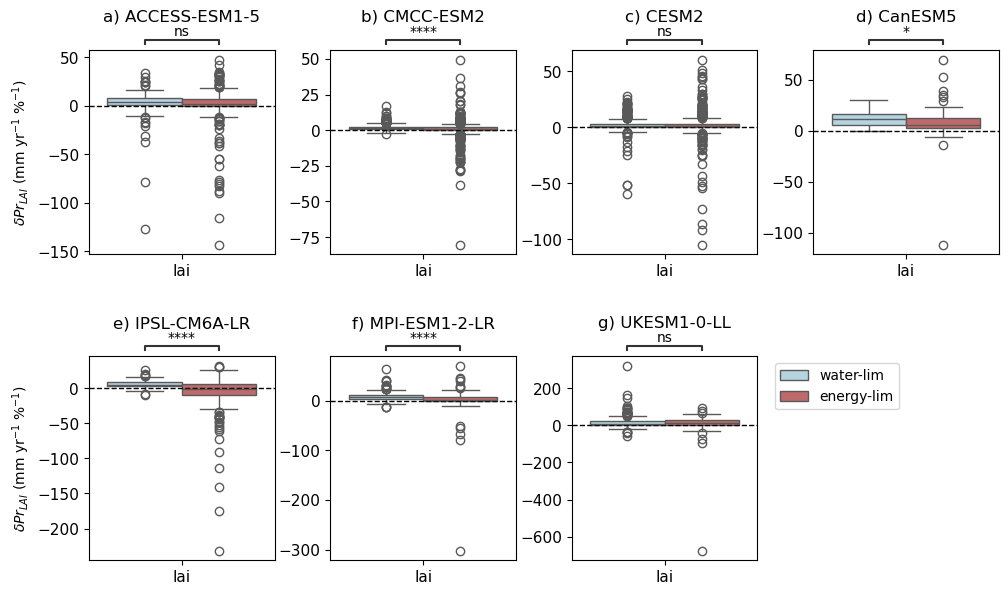

/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro

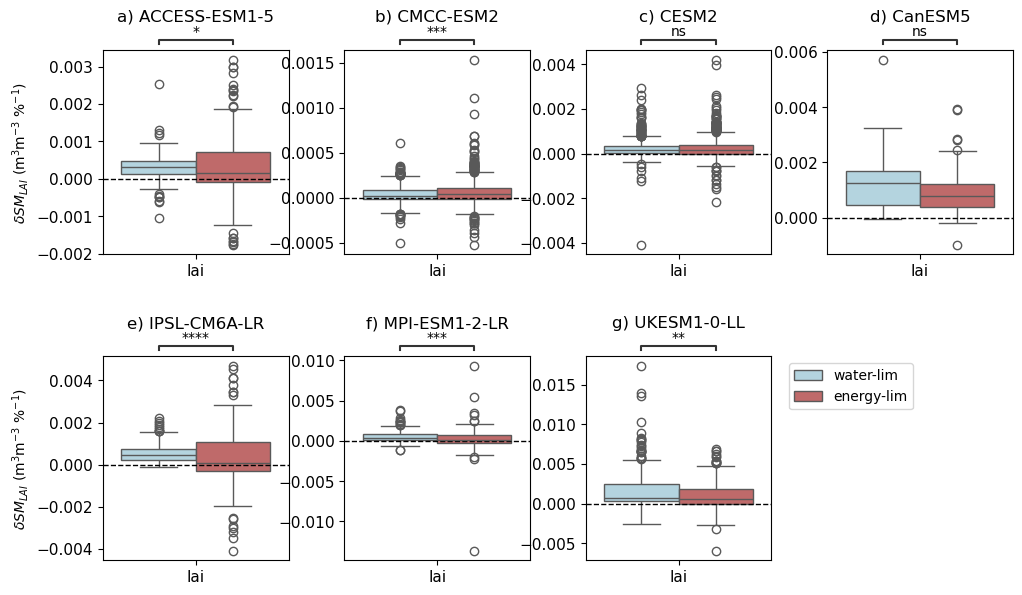

In [23]:
from statannotations.Annotator import Annotator
import seaborn.categorical


def plot_sensitivity_boxplots(sensitivity_list, valid_models, ylabel, title):
    width_inch, height_inch = 13, 6
    fig = plt.figure(figsize=(width_inch, height_inch))
    grid = gridspec.GridSpec(2, 4)
    panels = ["a) ", "b) ", "c) ", "d) ", "e) ", "f) ", "g) "]

    plot_idx = 0
    for m, mm in enumerate(models):
        if mm not in valid_models or sensitivity_list[m] is None:
            continue

        data = sensitivity_list[m]
        water = data.where(mask_treefrac_pos[m].notnull()).where(mask_aff_water[m].notnull())
        energy = data.where(mask_treefrac_pos[m].notnull()).where(mask_aff_energy[m].notnull())

        water_df = water.stack(cell=["lon", "lat"]).dropna(dim='cell').to_dataframe(name="value")[["value"]]
        water_df["regime"] = "water-lim"
        energy_df = energy.stack(cell=["lon", "lat"]).dropna(dim='cell').to_dataframe(name="value")[["value"]]
        energy_df["regime"] = "energy-lim"
        df = pd.concat([water_df, energy_df], axis=0)
        df["variable"] = "lai"

        row, col = divmod(plot_idx, 4)
        axs = fig.add_subplot(grid[row, col])
        sns.boxplot(data=df, x='variable', y='value', hue='regime', palette=['lightblue', 'indianred'], ax=axs)
        axs.axhline(y=0, color="black", linestyle="--", linewidth=1)

        axs.legend_.remove()
        axs.set_xlabel("")
        axs.tick_params(labelsize=11)
        axs.set_title(panels[plot_idx] + mm, y=1.1)
        axs.set_ylabel(ylabel if plot_idx in [0, 4] else "")
        if plot_idx == 3:
            axs.legend(loc='upper right', bbox_to_anchor=(0.5, -0.5), fontsize=10)

        box_pairs = [(("lai", "water-lim"), ("lai", "energy-lim"))]
        annotator = Annotator(axs, box_pairs, data=df, x='variable', y='value', hue='regime')
        annotator.configure(test='Mann-Whitney', text_format='star', loc='outside', comparisons_correction="bonferroni", verbose=0)
        annotator.apply_and_annotate()

        plot_idx += 1

    fig.tight_layout()
    fig.subplots_adjust(bottom=0.1, top=0.95, left=0.1, right=0.8, wspace=0.3, hspace=0.5)

    output_file = os.path.join(out_path, title) + ".png"
    plt.savefig(output_file, bbox_inches='tight', dpi=500)
    plt.show()
    plt.close()


plot_sensitivity_boxplots(
    dPr_LAI, models,
    ylabel=r"$\delta Pr_{LAI}$ (mm yr$^{-1}$ %$^{-1}$)",
    title="dPrdLAIpct-1 boxplot",
)

plot_sensitivity_boxplots(
    dSM_LAI, models_mrsol,
    ylabel=r"$\delta SM_{LAI}$ (m$^3$m$^{-3}$ %$^{-1}$)",
    title="dSMdLAIpct-1 boxplot",
)


/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro

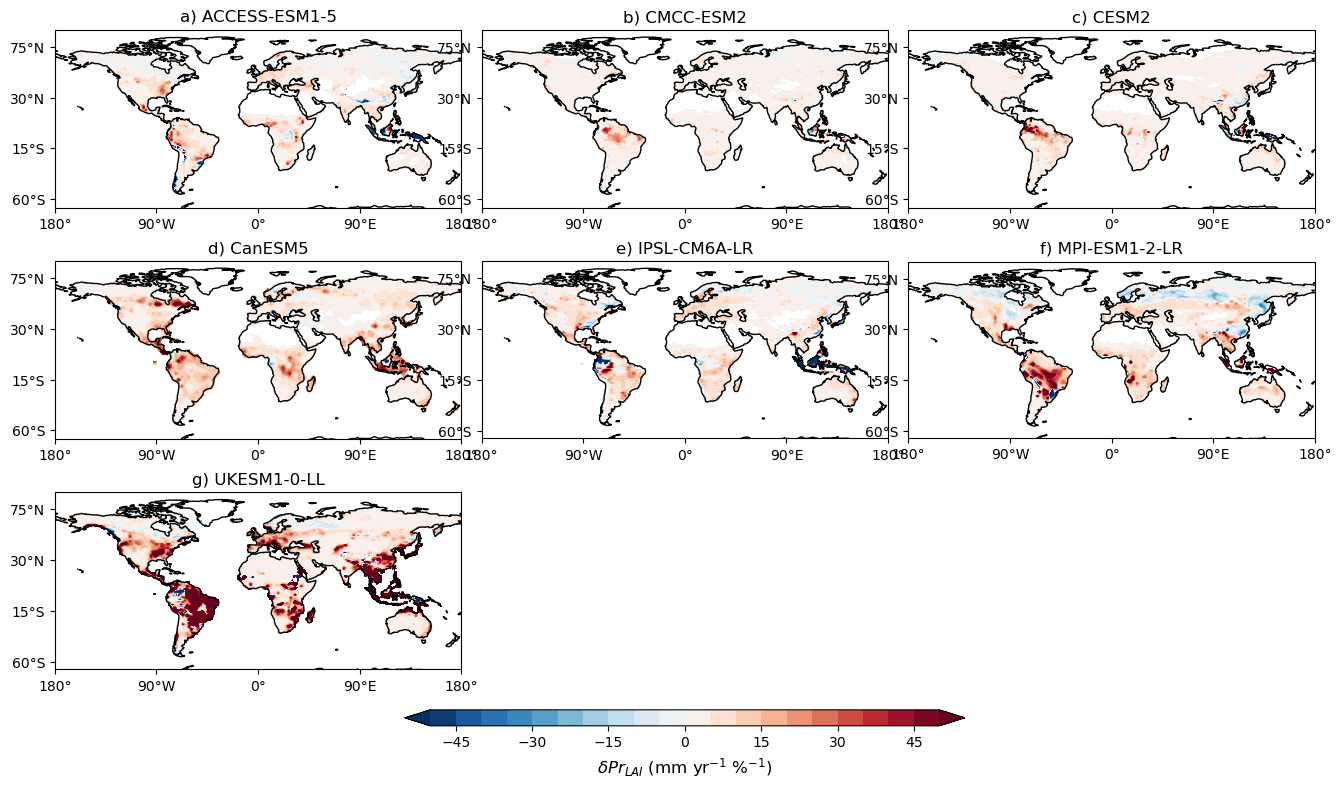

/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro

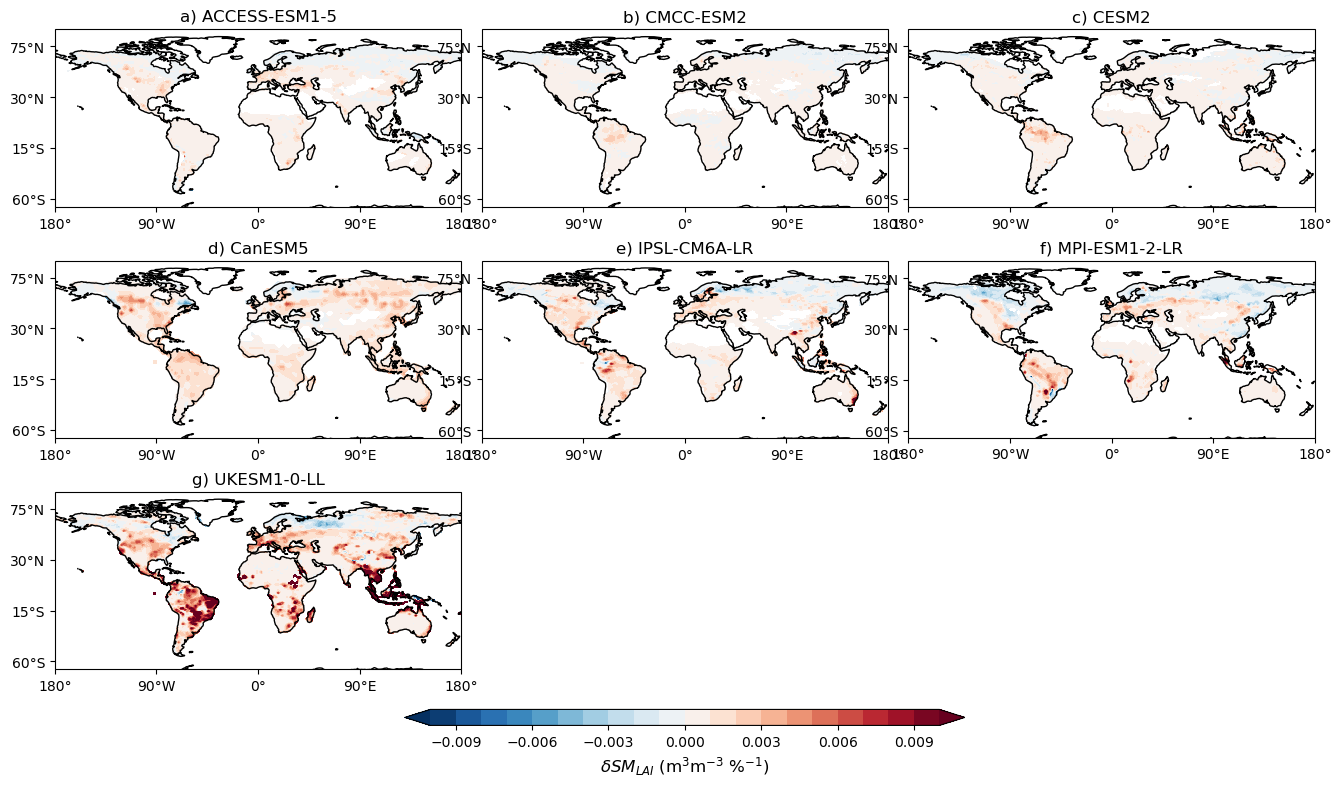

In [24]:
def plot_sensitivity_map(sensitivity_list, valid_models, clevs, cbar_label, title):
    fig, axs = plt.subplots(nrows=3, ncols=3, figsize=(14, 8), subplot_kw={'projection': ccrs.PlateCarree()})
    axs = axs.flatten()
    panels = ["a) ", "b) ", "c) ", "d) ", "e) ", "f) ", "g) "]

    plot_idx = 0
    cf = None
    for m, mm in enumerate(models):
        if mm not in valid_models or sensitivity_list[m] is None:
            continue

        data = sensitivity_list[m]
        lats = data.lat
        data_c, lons = add_cyclic_point(data, coord=data['lon'])

        cf = axs[plot_idx].contourf(lons, lats, data_c, clevs, transform=ccrs.PlateCarree(), cmap="RdBu_r", extend='both')
        axs[plot_idx].coastlines()

        axs[plot_idx].set_xticks(np.arange(-180, 181, 90), crs=ccrs.PlateCarree())
        axs[plot_idx].xaxis.set_major_formatter(cticker.LongitudeFormatter())
        axs[plot_idx].set_yticks(np.arange(-60, 91, 45), crs=ccrs.PlateCarree())
        axs[plot_idx].yaxis.set_major_formatter(cticker.LatitudeFormatter())
        axs[plot_idx].set_title(panels[plot_idx] + mm)

        plot_idx += 1

    for i in range(plot_idx, len(axs)):
        fig.delaxes(axs[i])

    fig.subplots_adjust(bottom=0.15, top=0.95, left=0.05, right=0.95, wspace=0.05, hspace=0.3)
    cb_ax = fig.add_axes([0.3, 0.08, 0.4, 0.02])
    cbar = plt.colorbar(cf, cax=cb_ax, extend='both', orientation='horizontal')
    cbar.ax.set_xlabel(cbar_label, fontsize=12)

    output_file = os.path.join(out_path, title) + ".png"
    plt.savefig(output_file, bbox_inches='tight', dpi=500)
    plt.show()
    plt.close()


plot_sensitivity_map(
    dPr_LAI, models,
    clevs=np.arange(-50, 51, 5),
    cbar_label=r"$\delta Pr_{LAI}$ (mm yr$^{-1}$ %$^{-1}$)",
    title="dPrdLAIpct-1 map",
)

plot_sensitivity_map(
    dSM_LAI, models_mrsol,
    clevs=np.arange(-0.01, 0.0101, 0.001),
    cbar_label=r"$\delta SM_{LAI}$ (m$^3$m$^{-3}$ %$^{-1}$)",
    title="dSMdLAIpct-1 map",
)


In [25]:
def print_weighted_summary(sensitivity_list, valid_models, label, unit):
    print(f"\n--- {label} ({unit}) ---")
    values = []
    for m, mm in enumerate(models):
        if mm not in valid_models or sensitivity_list[m] is None:
            continue
        masked = sensitivity_list[m].where(mask_treefrac_pos[m].notnull())
        mean_val = float(masked.weighted(cell_weight(masked)).mean(skipna=True))
        values.append(mean_val)
        print(f"{mm}: {mean_val:.4f} {unit}  (area-weighted mean, treeFrac increase > 10% cells)")
    print(f"Multi-model mean: {np.mean(values):.4f} +/- {np.std(values):.4f} {unit}")


print_weighted_summary(dPr_LAI, models, "Precipitation sensitivity to LAI", "mm yr-1 %-1")
print_weighted_summary(dSM_LAI, models_mrsol, "Soil moisture sensitivity to LAI", "m3 m-3 %-1")



--- Precipitation sensitivity to LAI (mm yr-1 %-1) ---


/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


ACCESS-ESM1-5: 1.3495 mm yr-1 %-1  (area-weighted mean, treeFrac increase > 10% cells)


/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


CMCC-ESM2: 1.2894 mm yr-1 %-1  (area-weighted mean, treeFrac increase > 10% cells)


/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


... (18 outputs left out)

IPSL-CM6A-LR: 0.0004 m3 m-3 %-1  (area-weighted mean, treeFrac increase > 10% cells)


/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


MPI-ESM1-2-LR: 0.0005 m3 m-3 %-1  (area-weighted mean, treeFrac increase > 10% cells)
UKESM1-0-LL: 0.0015 m3 m-3 %-1  (area-weighted mean, treeFrac increase > 10% cells)
Multi-model mean: 0.0006 +/- 0.0005 m3 m-3 %-1


/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


## End-of-century (2071-2100) mean $\Delta$ / $\Delta$treeFrac sensitivity

Simpler companion diagnostic to the LAI-regression sensitivity above: instead of a
per-year regression, this takes the **already-computed 30-year (2071-2100) mean** afforestation
signal (`xr_delta`, `xr_delta_pft`, both `ssp126Lu - ssp370`) and forms a direct ratio

    (mean Pr_aff - mean Pr_ctl) / (mean treeFrac_aff - mean treeFrac_ctl)

grid-cell by grid-cell (and the analogous ratio for soil moisture). Because the denominator is
restricted to |treeFrac change| > 10% (`mask_treefrac_pos` / `mask_treefrac_neg`), it never
approaches zero, so this ratio is well behaved without detrending or gap-filling.

Unlike the section above, this one also splits by the **direction** of the treeFrac change:
afforested cells (`mask_treefrac_pos`, treeFrac +>10%) vs. deforested/non-forested cells
(`mask_treefrac_neg`, treeFrac -<-10%), each further split by water-/energy-limited regime
(`mask_aff_water` / `mask_aff_energy`) -- four categories in total. Bars show the multi-model
mean +/- std; symbols show each individual model.

In [26]:
categories = [
    "Afforested\n(water-lim)", "Afforested\n(energy-lim)",
    "Deforested\n(water-lim)", "Deforested\n(energy-lim)",
]


def masked_weighted_mean(da, bool_mask):
    m = da.where(bool_mask)
    if int(m.notnull().sum()) == 0:
        return np.nan
    return float(m.weighted(cell_weight(m)).mean(skipna=True))


def ratio_sensitivity_by_category(ratio_list):
    """Per-model, area-weighted mean of a Delta/DeltatreeFrac ratio map in each of the four
    afforested/deforested x water-/energy-limited categories. Returns {category: [per-model values]}."""
    results = {c: [] for c in categories}
    for m, mm in enumerate(models):
        ratio = ratio_list[m]
        results["Afforested\n(water-lim)"].append(
            masked_weighted_mean(ratio, mask_treefrac_pos[m].notnull() & mask_aff_water[m].notnull()))
        results["Afforested\n(energy-lim)"].append(
            masked_weighted_mean(ratio, mask_treefrac_pos[m].notnull() & mask_aff_energy[m].notnull()))
        results["Deforested\n(water-lim)"].append(
            masked_weighted_mean(ratio, mask_treefrac_neg[m].notnull() & mask_aff_water[m].notnull()))
        results["Deforested\n(energy-lim)"].append(
            masked_weighted_mean(ratio, mask_treefrac_neg[m].notnull() & mask_aff_energy[m].notnull()))
    return results


In [27]:
# xr_delta[m]["pr"] is a climatological MONTHLY mean difference (mm/month); x12 converts it
# to the equivalent mean ANNUAL total difference (mm/yr) -- exact since both are linear
# operators over the same 30-year/360-month window.
# xr_delta[m]["mrsol"] is already a volumetric water content (m3 m-3), so no conversion needed.
dPr_dTree_ratio = []
dSM_dTree_ratio = []
for m, mm in enumerate(models):
    dPr_dTree_ratio.append((xr_delta[m]["pr"] * 12) / xr_delta_pft[m]["treeFrac"])
    dSM_dTree_ratio.append(xr_delta[m]["mrsol"] / xr_delta_pft[m]["treeFrac"])

results_pr_ratio = ratio_sensitivity_by_category(dPr_dTree_ratio)
results_sm_ratio = ratio_sensitivity_by_category(dSM_dTree_ratio)


/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: divide by zero encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: divide by zero encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: divide by zero encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: divide by zero encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: divide by zero encountered in divide
  return self.func(*new_argspec)
/Users/matteomastrop

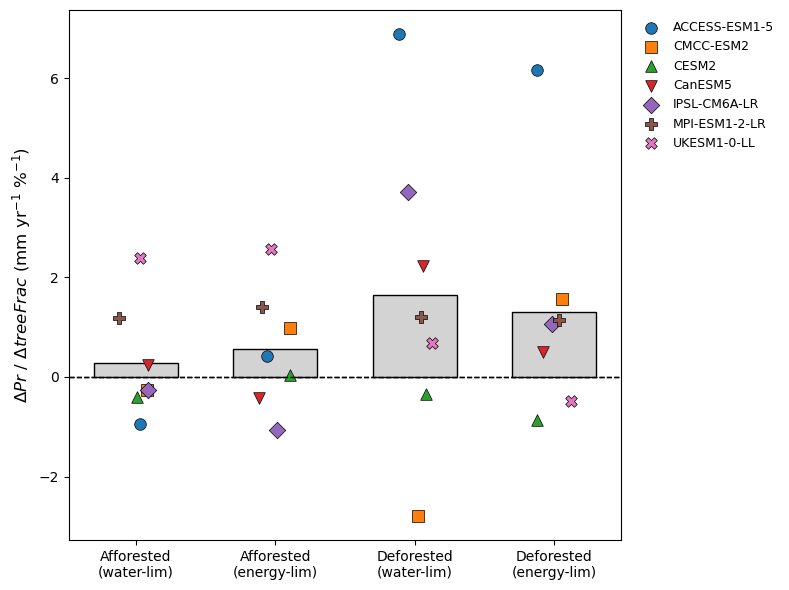

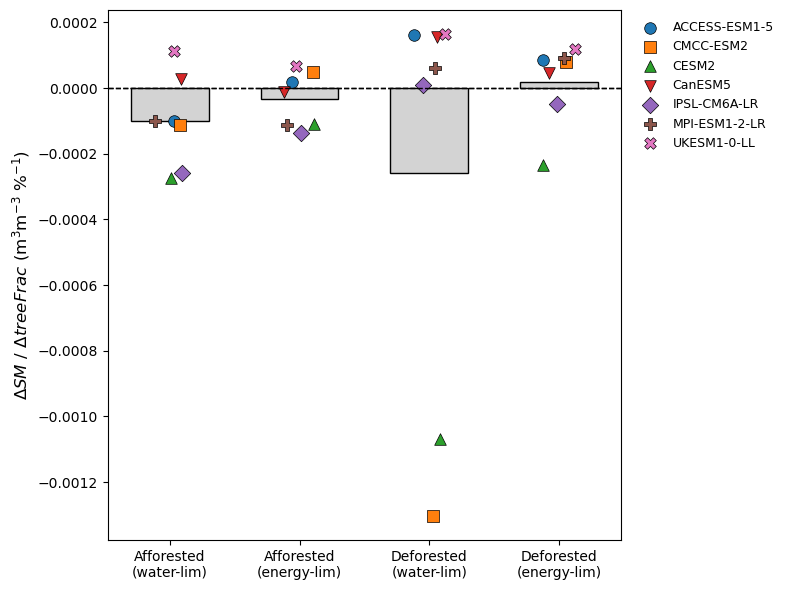

In [28]:
def plot_ratio_barplot(results, ylabel, title):
    fig, ax = plt.subplots(figsize=(8, 6))
    x = np.arange(len(categories))
    means = [np.nanmean(results[c]) for c in categories]
    stds = [np.nanstd(results[c]) for c in categories]

    ax.bar(x, means, capsize=4, color="lightgrey", edgecolor="black", width=0.6, zorder=1) #yerr=stds
    ax.axhline(0, color="black", linewidth=1, linestyle="--", zorder=0)

    markers = ['o', 's', '^', 'v', 'D', 'P', 'X']
    colors = plt.get_cmap("tab10").colors

    jitter_rng = np.random.default_rng(0)
    for mi, mm in enumerate(models):
        jitter = (jitter_rng.random(len(categories)) - 0.5) * 0.25
        vals = [results[c][mi] for c in categories]
        ax.scatter(x + jitter, vals, marker=markers[mi % len(markers)], color=colors[mi % len(colors)],
                   s=70, edgecolor="black", linewidth=0.5, zorder=2, label=mm)

    ax.set_xticks(x)
    ax.set_xticklabels(categories, fontsize=10)
    ax.axhline(0, color="black", linewidth=1, linestyle="--")
    ax.set_ylabel(ylabel, fontsize=12)
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9, frameon=False)
    fig.tight_layout()

    output_file = os.path.join(out_path, title) + ".png"
    plt.savefig(output_file, bbox_inches="tight", dpi=500)
    plt.show()
    plt.close()


plot_ratio_barplot(
    results_pr_ratio,
    ylabel=r"$\Delta Pr\ /\ \Delta treeFrac$ (mm yr$^{-1}$ %$^{-1}$)",
    title="dPr_dTreeFrac_30yr_barplot",
)

plot_ratio_barplot(
    results_sm_ratio,
    ylabel=r"$\Delta SM\ /\ \Delta treeFrac$ (m$^3$m$^{-3}$ %$^{-1}$)",
    title="dSM_dTreeFrac_30yr_barplot",
)


## Societally relevant summary metrics: temperature vs. water trade-off per unit area afforested

The two ratio barplots above (`dPr_dTreeFrac_30yr_barplot`, `dSM_dTreeFrac_30yr_barplot`) express
sensitivities per **percent of a grid cell's area converted**. That is the right unit for
comparing models on different grids, but it is not a unit a policy audience can act on. This
section reframes the same underlying fields (`xr_delta`, `xr_delta_pft`, the same four
Afforested/Deforested x water-/energy-limited categories, the same masks and `cell_weight()`)
into two metrics with physical, decision-relevant units: **K per additional Mha afforested**, and
**m^3 of root-zone soil water per additional Mha afforested**. Together they summarise the
paper's local biophysical trade-off: the temperature benefit (or cost) and the water cost (or
benefit) that come with a given amount of land converted.

**Temperature and water are treated differently on purpose.** Temperature is an intensive
quantity -- grid cells cannot be summed to get a meaningful "total degrees" the way volumes of
water can be summed to get a total volume. So:

- **Temperature metric (K / Mha)**: for each grid cell, the local `dTs / dtreeFrac` sensitivity
  (K per percent of the cell converted, exactly as computed for the barplots above) is rescaled
  from "per percent of that cell" to "per Mha actually converted in that cell", using
  `cell_weight()` for the cell's physical area. This per-pixel *rate* is then averaged by
  `ratio_sensitivity_by_category()` -- the same function used for the Pr/SM ratios above -- which
  answers "in this category, what local Ts response should we expect, on average, per Mha
  planted".
- **Water metric (m^3 / Mha)**: soil water content *is* additive across space, so instead of
  averaging a per-pixel ratio, this sums the actual root-zone water volume change and the actual
  Mha converted separately across every pixel in a category, then divides the two totals. That is
  a true landscape-scale budget: "across all the land the scenario actually converts in this
  category, how many m^3 of root-zone water change come with each additional Mha".

The soil-moisture volume uses the same root-zone depth (0-2 m) already established for the
depth-weighted `mrsol` used throughout this notebook and `water_avail_final.ipynb` (see
`DEPTH_RANGE`/`RHO_W` in Section 2's preprocessing, and `REVISION_NOTES.md`) -- this is the
depth-weighting fix the earlier `dSM/dtreeFrac` ratio above already relies on, applied here to
recover an actual volume rather than a dimensionless m^3 m^-3 fraction.

**Grid alignment**: `xr_delta`/`mask_aff_water`/`mask_aff_energy` (the main per-model grid) and
`xr_delta_pft`/`mask_treefrac_pos`/`mask_treefrac_neg` (the PFT grid) are snapped onto a common
set of lat/lon coordinates right after each is created (see the cells right after `xr_delta`'s
and `mask_aff_water`/`mask_aff_energy`'s creation, above in the "Afforestation and regime
masking" section) -- without this, CMCC-ESM2 and CESM2 silently came out as all-NaN wherever the
two grids get combined, here and in the ratios above, because the two source products' lat/lon
coordinates don't match to full float precision for those two models even though both are
nominally on the same grid.

In [29]:
# --- Shared conversion: Delta(treeFrac) expressed as Mha actually converted per grid cell ---
# xr_delta_pft[m]["treeFrac"] is in percent; dividing by 100 gives the converted fraction of the
# cell, and multiplying by the cell's physical area (cell_weight(), m^2) gives the physical area
# converted, in m^2. 1 Mha = 1e6 ha = 1e10 m^2. Kept signed: positive for afforested pixels
# (mask_treefrac_pos), negative for deforested pixels (mask_treefrac_neg), so a single array
# serves as the denominator for both categories below without extra bookkeeping.
M2_PER_MHA = 1e10
ROOT_ZONE_DEPTH_M = 2.0  # matches DEPTH_RANGE = (0, 2) used for the depth-weighted mrsol above

area_mha_delta = []
for m, mm in enumerate(models):
    area_mha_delta.append(
        (xr_delta_pft[m]["treeFrac"] / 100) * cell_weight(xr_delta_pft[m]) / M2_PER_MHA
    )

### Metric 1 -- local temperature response per additional Mha afforested (K / Mha)

/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: divide by zero encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: divide by zero encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: divide by zero encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropie

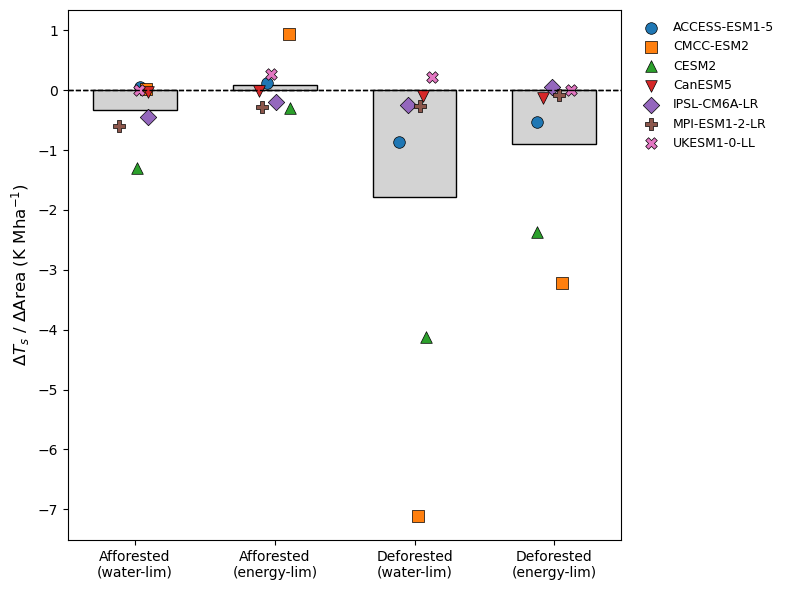

In [30]:
# Local Ts response per Mha converted, per grid cell: same numerator (xr_delta[m]["ts"]) as any
# dTs/dtreeFrac sensitivity, denominator switched from "% of cell converted" to "Mha converted in
# that cell" via area_mha_delta above. `ts` (not `tas`) matches the temperature variable already
# used everywhere else in this codebase (regime_limit, the IBPM decomposition in
# rough_tran_scale_v1.ipynb). Aggregated with the same ratio_sensitivity_by_category() used for
# the dPr/dSM ratios above -- safe now that xr_delta and mask_aff_water/mask_aff_energy are
# grid-aligned to mask_treefrac_pos/mask_treefrac_neg at their source (see the "Afforestation and
# regime masking" section).
dT_dMha_ratio = []
for m, mm in enumerate(models):
    dT_dMha_ratio.append(xr_delta[m]["ts"] / area_mha_delta[m])

results_dT_permha = ratio_sensitivity_by_category(dT_dMha_ratio)

plot_ratio_barplot(
    results_dT_permha,
    ylabel=r"$\Delta T_s\ /\ \Delta$Area (K Mha$^{-1}$)",
    title="dT_dMha_30yr_barplot",
)

### Metric 2 -- root-zone water volume change per additional Mha afforested (m$^3$ / Mha)

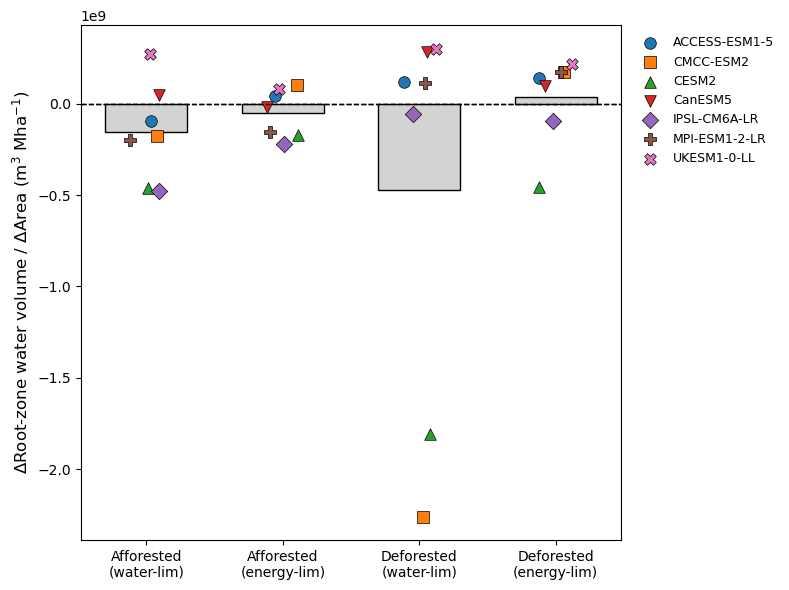

In [31]:
def total_ratio_by_category(numerator_list, denominator_list):
    """Category-level SUM(numerator) / SUM(denominator) across all pixels in the category mask,
    per model -- unlike ratio_sensitivity_by_category() (the area-weighted MEAN of an
    already-formed per-pixel ratio, used for the intensive temperature metric above), this sums
    the numerator and denominator separately before dividing. That is the physically appropriate
    aggregation for an EXTENSIVE (additive) quantity like water volume, where the landscape-scale
    total m^3 change per total Mha converted is the societally meaningful number -- summing a
    per-pixel m^3/Mha ratio the way the temperature metric does would double-count small,
    heavily-converted cells relative to large, lightly-converted ones. Safe now that
    mask_aff_water/mask_aff_energy are grid-aligned to mask_treefrac_pos/mask_treefrac_neg at
    their source (see the "Afforestation and regime masking" section)."""
    def masked_sum(da, bool_mask):
        m = da.where(bool_mask)
        if int(m.notnull().sum()) == 0:
            return np.nan
        return float(m.sum(skipna=True))

    masks_by_category = {
        "Afforested\n(water-lim)": lambda m: mask_treefrac_pos[m].notnull() & mask_aff_water[m].notnull(),
        "Afforested\n(energy-lim)": lambda m: mask_treefrac_pos[m].notnull() & mask_aff_energy[m].notnull(),
        "Deforested\n(water-lim)": lambda m: mask_treefrac_neg[m].notnull() & mask_aff_water[m].notnull(),
        "Deforested\n(energy-lim)": lambda m: mask_treefrac_neg[m].notnull() & mask_aff_energy[m].notnull(),
    }

    results = {c: [] for c in categories}
    for m, mm in enumerate(models):
        num, den = numerator_list[m], denominator_list[m]
        for cat, mask_fn in masks_by_category.items():
            mask = mask_fn(m)
            num_sum = masked_sum(num, mask)
            den_sum = masked_sum(den, mask)
            ratio = num_sum / den_sum if den_sum and not np.isnan(den_sum) else np.nan
            results[cat].append(ratio)
    return results


# Root-zone soil water volume change per grid cell, m^3: volumetric content change (m3 m-3) x
# root-zone depth (m) x cell area (m^2). mrsol here is the already depth-weighted (0-2 m) field
# built in Section 2's preprocessing and merged into xr_aff/xr_ctl (see the "kg m-2 (mass content
# per layer) -> m3 m-3" cell above), so xr_delta[m]["mrsol"] is directly usable.
water_volume_m3 = []
for m, mm in enumerate(models):
    water_volume_m3.append(xr_delta[m]["mrsol"] * ROOT_ZONE_DEPTH_M * cell_weight(xr_delta[m]))

results_water_permha = total_ratio_by_category(water_volume_m3, area_mha_delta)

plot_ratio_barplot(
    results_water_permha,
    ylabel=r"$\Delta$Root-zone water volume / $\Delta$Area (m$^3$ Mha$^{-1}$)",
    title="dWaterVolume_dMha_30yr_barplot",
)

### Summary table (per model, per category) and paste-ready text

In [32]:
summary_rows = []
for cat in categories:
    for m, mm in enumerate(models):
        summary_rows.append({
            "category": cat.replace("\n", " "),
            "model": mm,
            "dT_per_Mha_K": results_dT_permha[cat][m],
            "dWaterVolume_per_Mha_m3": results_water_permha[cat][m],
        })

df_metrics_summary = pd.DataFrame(summary_rows)

# Surface any remaining gaps explicitly, rather than letting them pass silently as blank bars.
missing = df_metrics_summary[
    df_metrics_summary["dT_per_Mha_K"].isna() | df_metrics_summary["dWaterVolume_per_Mha_m3"].isna()
]
if len(missing):
    print("NOTE -- no data in these model/category combinations (zero grid cells matched the")
    print("category mask): check whether that model genuinely has no pixels crossing the")
    print("+/-10% treeFrac threshold in this regime, vs. a remaining grid-alignment issue.")
    print(missing.to_string(index=False))
    print()

print("=" * 96)
print("SOCIETALLY RELEVANT SUMMARY METRICS -- per model, per category")
print("=" * 96)
with pd.option_context("display.float_format", "{:.4g}".format, "display.width", 120):
    print(df_metrics_summary.to_string(index=False))

print("\nMulti-model mean +/- std, by category:")
for cat in categories:
    dT_vals = [v for v in results_dT_permha[cat] if not np.isnan(v)]
    w_vals = [v for v in results_water_permha[cat] if not np.isnan(v)]
    dT_txt = f"{np.mean(dT_vals):.3g} +/- {np.std(dT_vals):.3g} K/Mha" if dT_vals else "n/a"
    w_txt = f"{np.mean(w_vals):.3g} +/- {np.std(w_vals):.3g} m3/Mha" if w_vals else "n/a"
    print(f"  {cat.replace(chr(10), ' '):28s}  dT: {dT_txt:22s}  dWaterVolume: {w_txt}")

csv_path = os.path.join(out_path, "societal_metrics_summary_30yr.csv")
df_metrics_summary.to_csv(csv_path, index=False)
print(f"\nSaved: {csv_path}")

SOCIETALLY RELEVANT SUMMARY METRICS -- per model, per category
               category         model  dT_per_Mha_K  dWaterVolume_per_Mha_m3
 Afforested (water-lim) ACCESS-ESM1-5       0.04777               -9.543e+07
 Afforested (water-lim)     CMCC-ESM2       0.01833                -1.78e+08
 Afforested (water-lim)         CESM2        -1.305               -4.609e+08
 Afforested (water-lim)       CanESM5      -0.02838                5.015e+07
 Afforested (water-lim)  IPSL-CM6A-LR       -0.4489               -4.784e+08
 Afforested (water-lim) MPI-ESM1-2-LR       -0.6024               -1.973e+08
 Afforested (water-lim)   UKESM1-0-LL      0.004981                2.756e+08
Afforested (energy-lim) ACCESS-ESM1-5         0.126                4.414e+07
Afforested (energy-lim)     CMCC-ESM2        0.9362                1.038e+08
Afforested (energy-lim)         CESM2       -0.3025                -1.71e+08
Afforested (energy-lim)       CanESM5     -0.006268               -1.906e+07
Afforested (e

**Paste-ready methods text:**

> To translate the grid-cell sensitivities above into a societally interpretable summary, we
> computed two additional metrics for each model and each of the four land-cover/evaporative-regime
> categories (afforested/deforested x water-/energy-limited). (1) The **temperature response per
> unit area converted** (K Mha$^{-1}$) is the area-weighted mean, across all grid cells in a
> category, of the local end-of-century (2071-2100) `dTs / dtreeFrac` sensitivity rescaled from
> "per percent of a grid cell converted" to "per Mha actually converted in that cell" -- an
> intensive local rate, since local temperature responses are not additive across space. (2) The
> **root-zone soil water volume change per unit area converted** (m$^3$ Mha$^{-1}$) is instead a
> true landscape-scale budget: the total root-zone (0-2 m) soil water volume change summed across
> all grid cells in a category, divided by the total land area (Mha) converted across those same
> cells -- appropriate because, unlike temperature, water volume is additive across space. Both
> metrics reuse the same afforestation/deforestation and evaporative-regime masks (>10%/<-10%
> `treeFrac` change; correlation-based water-/energy-limited classification) as the
> `dPr/dSM per dtreeFrac` sensitivities above.

## Societally relevant summary metrics for afforested regions as a whole (water- + energy-limited combined)

The two metrics above (`dT_dMha_30yr_barplot`, `dWaterVolume_dMha_30yr_barplot`) are reported
separately for water-limited and energy-limited afforested cells. This adds the single number a
non-technical reader will actually ask for: the same two metrics computed over **all** afforested
cells (`mask_treefrac_pos`), regardless of evaporative regime -- i.e. water-limited and
energy-limited cells combined into one "Afforested (all regimes)" category. Same underlying
fields, masks (`mask_treefrac_pos`, not further split), and units as above -- no new data, no new
assumptions beyond dropping the regime split.

Note on what "combined" means here: this uses every afforested cell (`mask_treefrac_pos`),
including any that `regime_limit` could not classify as clearly water- or energy-limited. If you
instead want the union of *only* the regime-classified afforested cells (i.e. exclude cells with
an ambiguous/unclassified regime), swap `mask_treefrac_pos[m]` below for
`mask_treefrac_pos[m].where(mask_aff_water[m].notnull() | mask_aff_energy[m].notnull())` -- flag
this to me if that's the definition you want and I'll make the change.


In [33]:
def ratio_sensitivity_whole(ratio_list, mask_list):
    """Area-weighted mean of a per-pixel ratio map across ALL pixels in mask_list[m] -- the
    single-category ('as a whole') counterpart to ratio_sensitivity_by_category()'s
    water-/energy-limited split. Same masked_weighted_mean() used for the intensive
    temperature metric above."""
    return [masked_weighted_mean(ratio_list[m], mask_list[m].notnull()) for m in range(len(models))]


def total_ratio_whole(numerator_list, denominator_list, mask_list):
    """SUM(numerator)/SUM(denominator) across ALL pixels in mask_list[m] -- the 'as a whole'
    counterpart to total_ratio_by_category(), for the extensive water-volume metric."""
    out = []
    for m in range(len(models)):
        mask = mask_list[m].notnull()
        num = numerator_list[m].where(mask)
        den = denominator_list[m].where(mask)
        num_sum = float(num.sum(skipna=True)) if int(num.notnull().sum()) > 0 else np.nan
        den_sum = float(den.sum(skipna=True)) if int(den.notnull().sum()) > 0 else np.nan
        out.append(num_sum / den_sum if den_sum and not np.isnan(den_sum) else np.nan)
    return out


results_dT_permha_whole = ratio_sensitivity_whole(dT_dMha_ratio, mask_treefrac_pos)
results_water_permha_whole = total_ratio_whole(water_volume_m3, area_mha_delta, mask_treefrac_pos)

summary_rows_whole = []
for m, mm in enumerate(models):
    summary_rows_whole.append({
        "category": "Afforested (all regimes)",
        "model": mm,
        "dT_per_Mha_K": results_dT_permha_whole[m],
        "dWaterVolume_per_Mha_m3": results_water_permha_whole[m],
    })
df_metrics_summary_whole = pd.DataFrame(summary_rows_whole)

missing_whole = df_metrics_summary_whole[
    df_metrics_summary_whole["dT_per_Mha_K"].isna() | df_metrics_summary_whole["dWaterVolume_per_Mha_m3"].isna()
]
if len(missing_whole):
    print("NOTE -- no data for these models (zero grid cells matched mask_treefrac_pos):")
    print(missing_whole.to_string(index=False))
    print()

print("=" * 96)
print("SOCIETALLY RELEVANT SUMMARY METRICS -- Afforested regions AS A WHOLE (water + energy combined)")
print("=" * 96)
with pd.option_context("display.float_format", "{:.4g}".format, "display.width", 120):
    print(df_metrics_summary_whole.to_string(index=False))

dT_vals = [v for v in results_dT_permha_whole if not np.isnan(v)]
w_vals = [v for v in results_water_permha_whole if not np.isnan(v)]
dT_txt = f"{np.mean(dT_vals):.3g} +/- {np.std(dT_vals):.3g} K/Mha" if dT_vals else "n/a"
w_txt = f"{np.mean(w_vals):.3g} +/- {np.std(w_vals):.3g} m3/Mha" if w_vals else "n/a"
print(f"\nMulti-model mean +/- std, Afforested (all regimes):  dT: {dT_txt}   dWaterVolume: {w_txt}")

csv_path_whole = os.path.join(out_path, "societal_metrics_summary_30yr_afforested_whole.csv")
df_metrics_summary_whole.to_csv(csv_path_whole, index=False)
print(f"\nSaved: {csv_path_whole}")


/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: divide by zero encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: divide by zero encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: divide by zero encountered in divide
  return self.func(*new_argspec)
/Users/matteomastropie

SOCIETALLY RELEVANT SUMMARY METRICS -- Afforested regions AS A WHOLE (water + energy combined)
                category         model  dT_per_Mha_K  dWaterVolume_per_Mha_m3
Afforested (all regimes) ACCESS-ESM1-5       0.09294               -2.224e+07
Afforested (all regimes)     CMCC-ESM2        0.4568               -3.795e+07
Afforested (all regimes)         CESM2        -0.845               -3.341e+08
Afforested (all regimes)       CanESM5     -0.009663               -7.296e+06
Afforested (all regimes)  IPSL-CM6A-LR       -0.3441               -3.685e+08
Afforested (all regimes) MPI-ESM1-2-LR       -0.5276               -1.879e+08
Afforested (all regimes)   UKESM1-0-LL       0.09743                2.124e+08

Multi-model mean +/- std, Afforested (all regimes):  dT: -0.154 +/- 0.409 K/Mha   dWaterVolume: -1.07e+08 +/- 1.89e+08 m3/Mha

Saved: /Users/matteomastropierro/Documents/afforestation_LUMIP/Submission/Figures/societal_metrics_summary_30yr_afforested_whole.csv


---
# Section 2 -- Companion descriptive analysis: distributions by land-cover class and
evaporative regime (from `water_avail_distributions.ipynb`)

Included **in full**, as its own self-contained sub-analysis (own config, own data load, own
`models`/`PERIOD`/`data_path`/`xr_aff`/`xr_ctl`/... -- these intentionally shadow Section 1's
identically-named variables; Section 2 does not read any Section-1 state, so this is safe as
long as this notebook is run top-to-bottom, exactly as the two original notebooks were each run
independently). It answers a narrower, descriptive question than Section 1 -- *"in the
multi-model-mean field, do afforested grid cells look statistically different from unchanged and
deforested ones?"* -- with the spatial-autocorrelation caveats spelled out in its own methods
cells below. Only Bug 1 and Bug 2 are fixed relative to the original; the analysis design,
statistics and all figures are otherwise unchanged.

# Multi-model-mean grid-cell distributions of dPr and dSM by land-cover class and evaporative regime

**Companion to `water_avail_bootstrap.ipynb`, not a replacement.** That notebook asks
*"is there an ensemble-robust effect?"*. This one asks a narrower, descriptive question:
*"in the multi-model-mean field, do afforested grid cells look different from unchanged and
deforested ones, at the locations where the scenario actually puts them?"* — and shows the full
distributions rather than a single mean.

---

## `_simple`: no spatial-shift permutation test, by explicit request

`water_avail_final.ipynb`'s version of this section additionally ran a **spatial-shift
permutation test**: the class-label field (afforested / deforested / unchanged) was rolled by a
random longitude offset and the statistic recomputed, to build a null distribution for "a class
geometry of this shape and size, placed anywhere in longitude at the same latitudes." That null
answers the question *"would an effect this size show up even if afforestation had landed
somewhere else?"*

That isn't the right null here: **afforestation location in these LUMIP runs is not random.** It
is set by the IAM's land-use trajectory (`ssp126Lu`), not drawn from a spatially-shiftable
distribution -- so a test built on "what if the geometry were placed at a random longitude" is
asking about scenario geometries that were never actually possible. What this notebook asks
instead is the more literal question: **does afforestation at the locations the scenario actually
puts it differ significantly from non-afforested land**, treating the class assignment as fixed.
Everything else (Section 1, the growing-season/regime masking, the data loading) is unchanged
from `water_avail_final.ipynb` -- this file only removes the shift-null machinery from Section
2's statistics (`spatial_shift_test`, `N_PERM`, `null_lo`/`null_hi`, `p_shift`, `outside_null`)
and the figure/interpretation logic built on it.

With the shift null gone, the **block-bootstrap CI on Cliff's delta** (resampling `BLOCK_DEG`
spatial tiles *within* each class, with replacement) is what's left to gauge how tightly the
effect size is pinned down, while still respecting spatial autocorrelation *inside* the real,
fixed class geometry. It is not perfectly calibrated either -- the false-positive-rate
calibration in `water_avail_final.ipynb` measured 33% at 10° tiles, plateauing near 22% at
30-45°, against a nominal 5%, because it can't see the sampling variability of *where* a class
sits in a smooth field. But that's precisely the variability this analysis doesn't need to
marginalize over: the class geometry is real and fixed by the scenario, not a draw from a
random-placement ensemble. Read the block-bootstrap CI, the raw Mann-Whitney/KS p-values
(FDR-corrected, still anti-conservative under spatial autocorrelation -- see below), and Cliff's
delta together, and weight the effect size over the p-value.

## Read this before using the p-values

A Mann-Whitney U test over grid cells will return a spectacularly small p-value here — typically
`p < 1e-20`. **That number is not evidence.** It is an artefact of three things, and a referee in
this field will identify all three:

1. **Grid cells are not independent samples.** Neighbouring cells share the same weather, the same
   soil column, the same land-surface parameterisation. The U test assumes `n1 * n2` independent
   pairs; the true information content is one to two orders of magnitude smaller. In the null
   calibration run in `water_avail_bootstrap.ipynb`, a per-grid-cell test rejected a **true null in
   93 % of replicates** at a nominal 5 %.
2. **Regridding makes this worse.** Interpolating every model onto a common 1x1 grid smooths the
   fields and *raises* spatial autocorrelation, so the naive p-value inflates further.
3. **Averaging the ensemble first removes model uncertainty from the analysis entirely.** The
   multi-model mean is much smoother than any single model. A test on the MMM field cannot tell you
   whether the models agree — it has already assumed they do. This is the deepest issue: the
   bootstrap notebook found no ensemble-robust signal, and no amount of cell-level testing on the
   MMM can overturn that, because it is answering a different question.

There is also a **confounding** problem independent of sample size: afforested cells are not
scattered uniformly -- they sit in particular biomes and latitude bands prescribed by the IAM.
A difference in dPr between afforested and unchanged cells may partly reflect *where these cells
are* rather than *what afforestation did there*. Using the paired anomaly `dX = ssp126Lu - ssp370`
(the default here) removes the mean-climate confound by differencing each cell against itself
before comparing classes. The latitude/biome confound is not removed by a statistical test here --
Fig. 9d below shows where each class actually sits, so a reader can judge how much of any
difference could be geographic rather than causal.

## What this notebook does instead

| Output | Status | Use in the paper |
|---|---|---|
| Distributions / ECDFs by class | descriptive | **Yes — this is the figure** |
| **Cliff's delta**, Hodges-Lehmann shift | sample-size independent effect size | **Yes — quote these** |
| **Block-bootstrap CI** on the effect size | precision under spatial autocorrelation, calibration imperfect (see above) | Report as the interval, with the caveat |
| Raw Mann-Whitney / KS p (FDR-corrected) | anti-conservative | Report only with the caveat, or not at all |
| Effective sample size `n_eff` | diagnostic | Methods / SI, to justify the above |

Measured false-positive rates under a **true null** on synthetic smooth fields with realistically
clustered classes (60 replicates, nominal 5 %; from `water_avail_final.ipynb`'s calibration --
not rerun here since nothing about the fields or classes changed):

| test | false positives |
|---|---|
| Kolmogorov-Smirnov over grid cells | 100 % |
| Mann-Whitney U over grid cells | 92 % |
| block-bootstrap CI on Cliff's delta | 33 % at 10°, 22 % at 45° — plateaus, never reaches nominal |

(The spatial-shift permutation measured 8% in that same calibration -- but that number describes
a test this notebook no longer runs, so it's dropped from the table rather than left dangling.)

In [34]:
import os
import glob
import itertools
import warnings

import numpy as np
import pandas as pd
import xarray as xr

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from scipy.stats import mannwhitneyu, ks_2samp, linregress
from scipy.stats import gaussian_kde
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore", category=RuntimeWarning)
xr.set_options(keep_attrs=True)

try:
    import xesmf as xe
    HAS_XESMF = True
except Exception:
    HAS_XESMF = False
print(f"xESMF available: {HAS_XESMF}  "
      f"({'conservative regridding' if HAS_XESMF else 'falling back to xarray bilinear interp'})")

xESMF available: True  (conservative regridding)


## 1. Configuration

In [35]:
work = "locale_mc"

if work == "levante":
    data_path = "/home/m/m301093/data/clean/"
    out_path  = "/home/m/m301093/results_biophys/"
if work == "locale_wnd":
    data_path = "G:/My Drive/MPIM/data/"
    out_path  = "G:/My Drive/MPIM/Figures/"
if work == "locale_mc":
    data_path = "/Users/matteomastropierro/Documents/afforestation_LUMIP/data/"
    out_path  = "/Users/matteomastropierro/Documents/afforestation_LUMIP/Submission/Figures/"

models = ["ACCESS-ESM1-5", "CMCC-ESM2", "CESM2", "CanESM5",
          "IPSL-CM6A-LR", "MPI-ESM1-2-LR", "UKESM1-0-LL"]

PERIOD  = slice("2071-01", "2100-12")
N_YEARS = 30

# --- common target grid ----------------------------------------------------
GRID_RES  = 1.0
LAT_RANGE = (-60, 90)
REGRID_METHOD = "conservative" if HAS_XESMF else "bilinear"

# --- what is plotted / tested ---------------------------------------------
VALUE_MODE = "delta"   # "delta"    -> dX = ssp126Lu - ssp370  (RECOMMENDED: removes the mean-climate
                       #               confound between geographically distinct classes)
                       # "relative" -> 100 * dX / X_ctl  (%)
                       # "absolute" -> X from the ssp126Lu run (NOT recommended: a class difference
                       #               then mostly reflects *where* the classes are, not the LUC effect)

# --- classification --------------------------------------------------------
TREE_POS    =  10.0
TREE_NEG    = -10.0
TREE_UNCH   =   2.0
MIN_LAI_CTL =   0.10
AGREE_FRAC  =   5 / 7   # a cell is assigned to a class only if >= this fraction of models agree.
                        # Classifying on the MMM alone would let one model with extreme land-use
                        # forcing define the mask for the whole ensemble.

REGIME_METHOD    = "raw"        # reverted to "raw" (pre-revision, non-deseasonalized) by explicit
                                 # user request, Aug 2026 -- "deseason" remains available and is
                                 # statistically the more defensible choice, see lumip_utils.py
REGIME_REFERENCE = "ctl"
REGIME_AGREE     = 5 / 7

GS_REFERENCE = "ctl"

# --- inference -------------------------------------------------------------
# NOTE (revision, `_simple` variant): N_PERM / spatial-shift permutation removed -- afforestation
# location is prescribed by the IAM, not random, so testing against a random-longitude placement
# of the class geometry isn't the right null here. See the Section-2 intro cell. The block
# bootstrap below is now the primary interval; MIN_CELLS/SEED/N_HL_PAIRS are unchanged.
N_BOOT      = 2000     # spatial block bootstrap for effect-size CIs -- the primary interval here
BLOCK_DEG   = 20.0     # tile size for the block bootstrap (calibration caveat: see intro cell /
                        # block_bootstrap_delta docstring -- not a perfectly calibrated test)
N_HL_PAIRS  = 200_000  # random pairs for the Hodges-Lehmann shift estimate
SEED        = 20260813
MIN_CELLS   = 30

# --- soil column -----------------------------------------------------------
DEPTH_RANGE      = (0, 2)
RHO_W            = 1000.0
IPSL_TOTAL_DEPTH = 2.0

FIG_PREFIX = "dist_simple_"   # distinct from water_avail_final.ipynb's "dist_" so the two
                               # notebooks' figures/CSVs don't overwrite each other in out_path

LANDCOVER = ["Afforested", "Deforested", "Unchanged"]
REGIMES   = ["water-lim", "energy-lim"]
SEASONS   = ["GS", "ANN"]
VARS      = {"pr": "sum", "mrsol": "mean"}

rng_global = np.random.default_rng(SEED)
print(f"target grid {GRID_RES}x{GRID_RES} deg, lat {LAT_RANGE}, regrid = {REGRID_METHOD}, "
      f"values = {VALUE_MODE}")

target grid 1.0x1.0 deg, lat (-60, 90), regrid = conservative, values = delta


## 2. Helper functions

In [36]:
def cell_weight(ds):
    R = 6.371e6
    dphi = np.deg2rad(ds.lat[1] - ds.lat[0])
    dlam = np.deg2rad(ds.lon[1] - ds.lon[0])
    dlat = R * dphi * xr.ones_like(ds.lon)
    dlon = R * dlam * np.cos(np.deg2rad(ds.lat))
    return dlon * dlat


def xr_fix_time(xr_in, date_start, date_end):
    if xr_in["time"].dt.calendar in ("noleap", "360_day"):
        xr_in = xr_in.convert_calendar(calendar="gregorian", align_on="date")
    time = pd.date_range(start=date_start, end=date_end, freq="ME").to_numpy(dtype="datetime64[ns]")
    return xr_in.assign_coords(time=time)


def xr_clean(xr_in, dims):
    data = xr_in.copy()
    for d in dims:
        if d in data.coords and d in data.dims:
            data = data.drop_vars(d); data = data.isel({d: 0})
        if d in data.coords:
            data = data.drop_vars(d)
        if d in data.dims and d not in data.coords:
            data = data.isel({d: 0})
        if data.attrs != {} and d in data.data_vars:
            data = data.drop_vars(d)
    return data


def lon180(ds):
    ds.coords["lon"] = (ds.coords["lon"] + 180) % 360 - 180
    return ds.sortby(ds.lon)


def lag_linregress_3D(x, y):
    x, y = xr.align(x, y)
    n = x.shape[0]
    xm, ym = x.mean(axis=0), y.mean(axis=0)
    xs, ys = x.std(axis=0), y.std(axis=0)
    cov = np.sum((x - xm) * (y - ym), axis=0) / n
    return {"cor": cov / (xs * ys)}


def deseason(da):
    out = da.groupby("time.month") - da.groupby("time.month").mean("time")
    return out.drop_vars("month", errors="ignore").transpose("time", "lat", "lon")

## 3. Load and preprocess (native grids)

Identical chain to `water_avail_bootstrap.ipynb`, including the depth-weighted `mrsol` conversion
to volumetric water content. All temporal reduction happens **here, on the native grid** — only
2-D maps are regridded afterwards, which is both cheaper and avoids interpolating noise.

In [37]:
def _load(scenario, suffix=""):
    out = []
    for mm in models:
        fp = glob.glob(os.path.join(data_path, f"xr_{scenario}_{mm}{suffix}.nc"))[0]
        out.append(xr.open_dataset(fp, drop_variables=["time_bnds", "lon_bnds", "lat_bnds"],
                                   engine="netcdf4", chunks={"time": 240}))
    return out

xr_aff     = _load("ssp126Lu")
xr_ctl     = _load("ssp370")
xr_aff_pft = _load("ssp126Lu", "_pft")
xr_ctl_pft = _load("ssp370",   "_pft")

i_can = models.index("CanESM5")
for ds in (xr_aff, xr_ctl):
    ds[i_can]["hfls"] = (ds[i_can].rsds - ds[i_can].rlds) - ds[i_can].hfss
    ds[i_can] = ds[i_can].rename({"ta": "tas"}).isel(plev=0)
    ds[i_can]["tas"] = (ds[i_can].ts + ds[i_can].tas) / 2

for i, mm in enumerate(models):
    for ds in (xr_aff, xr_ctl):
        ds[i]["pr"] = ds[i].pr * 86400 * ds[i].time.dt.days_in_month
        ds[i]["pr"].attrs = dict(units="mm month-1")
    xr_aff_pft[i]["lat"] = xr_aff[i].lat; xr_aff_pft[i]["lon"] = xr_aff[i].lon
    xr_ctl_pft[i]["lat"] = xr_ctl[i].lat; xr_ctl_pft[i]["lon"] = xr_ctl[i].lon

print("main + pft fields loaded")

/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_3756/3547634678.py:5: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 240. This could degrade performance. Instead, consider rechunking after loading.
  out.append(xr.open_dataset(fp, drop_variables=["time_bnds", "lon_bnds", "lat_bnds"],
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_3756/3547634678.py:5: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 240. This could degrade performance. Instead, consider rechunking after loading.
  out.append(xr.open_dataset(fp, drop_variables=["time_bnds", "lon_bnds", "lat_bnds"],
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_3756/3547634678.py:5: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 240. This could degrade performance. Instead, consider rechunking after loading.
  out.append(xr.open_dataset(fp, d

main + pft fields loaded


/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_3756/3547634678.py:5: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 240. This could degrade performance. Instead, consider rechunking after loading.
  out.append(xr.open_dataset(fp, drop_variables=["time_bnds", "lon_bnds", "lat_bnds"],
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_3756/3547634678.py:5: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 240. This could degrade performance. Instead, consider rechunking after loading.
  out.append(xr.open_dataset(fp, drop_variables=["time_bnds", "lon_bnds", "lat_bnds"],
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_3756/3547634678.py:5: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 240. This could degrade performance. Instead, consider rechunking after loading.
  out.append(xr.open_dataset(fp, d

In [38]:
xr_aff_mrsol, xr_ctl_mrsol = [], []
for mm in models:
    fa = glob.glob(os.path.join(data_path, f"mrsol_*_{mm}_ssp370-ssp126Lu_*.nc"))[0]
    fc = glob.glob(os.path.join(data_path, f"mrsol_*_{mm}_ssp370_*.nc"))[0]
    kw = dict(drop_variables=["time_bnds", "lon_bnds", "lat_bnds"], engine="netcdf4",
              chunks={"time": 240})
    xr_aff_mrsol.append(xr.open_dataset(fa, **kw))
    xr_ctl_mrsol.append(xr.open_dataset(fc, **kw))

i_ipsl = models.index("IPSL-CM6A-LR")
xr_aff_mrsol[i_ipsl] = xr_aff_mrsol[i_ipsl].rename({"solay": "depth"})
xr_ctl_mrsol[i_ipsl] = xr_ctl_mrsol[i_ipsl].rename({"solay": "depth"})

for i, mm in enumerate(models):
    xr_aff_mrsol[i] = xr_aff_mrsol[i].sel(lat=slice(*LAT_RANGE))
    xr_ctl_mrsol[i] = xr_ctl_mrsol[i].sel(lat=slice(*LAT_RANGE))
    is_ipsl = (mm == "IPSL-CM6A-LR")

    if not is_ipsl:
        dz_a = xr_aff_mrsol[i]["depth_bnds"].sel(depth=slice(*DEPTH_RANGE)).diff("bnds").squeeze("bnds")
        dz_c = xr_ctl_mrsol[i]["depth_bnds"].sel(depth=slice(*DEPTH_RANGE)).diff("bnds").squeeze("bnds")
        tot_a, tot_c = float(dz_a.sum("depth")), float(dz_c.sum("depth"))
    else:
        tot_a = tot_c = IPSL_TOTAL_DEPTH

    drops = ["dcpp_init_year", "member_id", "lon_bnds", "lat_bnds", "time_bnds", "bnds"]
    xr_aff_mrsol[i] = xr_fix_time(lon180(xr_clean(xr_aff_mrsol[i], drops)), "2015-01", "2101-01")
    xr_ctl_mrsol[i] = xr_fix_time(lon180(xr_clean(xr_ctl_mrsol[i], drops)), "2015-01", "2101-01")

    if not is_ipsl:
        a = xr_aff_mrsol[i].sel(depth=slice(*DEPTH_RANGE))["mrsol"].sum("depth") / (RHO_W * tot_a)
        c = xr_ctl_mrsol[i].sel(depth=slice(*DEPTH_RANGE))["mrsol"].sum("depth") / (RHO_W * tot_c)
    else:
        a = xr_aff_mrsol[i]["mrsol"].sum("depth") / (RHO_W * tot_a)
        c = xr_ctl_mrsol[i]["mrsol"].sum("depth") / (RHO_W * tot_c)

    assert a.sizes["lat"] == xr_aff[i].sizes["lat"] and a.sizes["lon"] == xr_aff[i].sizes["lon"]
    a = a.assign_coords(lat=xr_aff[i].lat, lon=xr_aff[i].lon).assign_attrs(units="m3 m-3")
    c = c.assign_coords(lat=xr_ctl[i].lat, lon=xr_ctl[i].lon).assign_attrs(units="m3 m-3")

    xr_aff[i] = xr.merge([xr_aff[i], a.rename("mrsol").to_dataset()])
    xr_ctl[i] = xr.merge([xr_ctl[i], c.rename("mrsol").to_dataset()])

print("soil moisture merged (depth-weighted, m3 m-3)")

soil moisture merged (depth-weighted, m3 m-3)


## 4. Growing season and evaporative regime (native grid)

Both are diagnosed from the **control** run, so neither the seasonal window nor the regime
stratum is itself modified by the land-cover perturbation.

In [39]:
# FIX 1 (Bug 1) + FIX 2 (Bug 2): local `classify_regime`/`phen_4gst` removed in favour
# of the shared, corrected implementations -- pure duplication removal, `classify_regime`
# here had the same deseasonalize-before-correlating logic as lumip_utils.classify_regime.
# REGIME_METHOD (config cell above) governs the actual method used at the call site below;
# it was reverted from "deseason" to "raw" (non-deseasonalized, pre-revision behaviour) by
# explicit user request, Aug 2026 -- see REVISION_NOTES.md.
# `phen_4gst` had the Bug 2 evergreen-test error (amp < 0.25 * lai_min instead of
# amp / lai_mean < 0.25); `compute_4gst` (imported from lumip_utils) is the fix.
#
# compute_4gst returns a packed xr.Dataset (gst_start_month, gst_end_month, gst_type)
# directly, instead of the original's manual xr.apply_ufunc(phen_4gst, ...,
# output_core_dims=[[],[],[]]) + manual 3-tuple unpacking, so the call site below is
# simplified accordingly. All downstream references to this notebook's own phenology
# fields are renamed .onset -> .gst_start_month and .offset -> .gst_end_month
# (there were none beyond this cell -- gs_mask_list is built here and used, by name
# only, everywhere else in this section).
import sys, os
sys.path.insert(0, os.path.abspath('.'))
from lumip_utils import compute_4gst, classify_regime


gs_mask_list, regime_native = [], []
ref_gs  = xr_ctl if GS_REFERENCE == "ctl" else xr_aff
ref_reg = xr_ctl if REGIME_REFERENCE == "ctl" else xr_aff

for m, mm in enumerate(models):
    lai_clim = ref_gs[m].lai.sel(time=PERIOD).groupby("time.month").mean("time").load()
    phen = compute_4gst(lai_clim, month_dim="month")
    onset, offset = phen.gst_start_month, phen.gst_end_month
    months = xr_aff[m].time.dt.month
    gs_mask_list.append(xr.where(onset <= offset,
                                 (months >= onset) & (months <= offset),
                                 (months >= onset) | (months <= offset)))
    regime_native.append(classify_regime(ref_reg[m].sel(time=PERIOD), REGIME_METHOD))
    print(f"  {mm:<16s} growing season + evaporative regime diagnosed")


  ACCESS-ESM1-5    growing season + evaporative regime diagnosed
  CMCC-ESM2        growing season + evaporative regime diagnosed
  CESM2            growing season + evaporative regime diagnosed
  CanESM5          growing season + evaporative regime diagnosed
  IPSL-CM6A-LR     growing season + evaporative regime diagnosed
  MPI-ESM1-2-LR    growing season + evaporative regime diagnosed
  UKESM1-0-LL      growing season + evaporative regime diagnosed


## 5. Reduce to 2-D maps, then regrid to the common 1x1 grid

Order matters: the 30-year temporal reduction is done on each model's **native** grid, and only the
resulting 2-D maps are interpolated. Regridding the monthly fields first would interpolate noise
and inflate spatial autocorrelation further.

`conservative` regridding (xESMF) is the correct choice for fluxes and fractional fields because it
conserves area integrals; `bilinear` via `xarray.interp` is the dependency-free fallback. The
categorical regime field is always regridded with **nearest neighbour** so that class labels are
never averaged into meaningless intermediate values.

In [40]:
lat_t = np.arange(LAT_RANGE[0] + GRID_RES / 2, LAT_RANGE[1], GRID_RES)
lon_t = np.arange(-180 + GRID_RES / 2, 180, GRID_RES)
target = xr.Dataset({"lat": ("lat", lat_t), "lon": ("lon", lon_t)})

_regridders = {}

def regrid(da, method=None):
    """Regrid a 2-D (lat, lon) DataArray onto the common target grid."""
    method = method or REGRID_METHOD
    da = da.sortby("lat").sortby("lon")
    if HAS_XESMF and method in ("conservative", "bilinear"):
        key = (da.sizes["lat"], da.sizes["lon"], method)
        if key not in _regridders:
            src = da.to_dataset(name="v")
            _regridders[key] = xe.Regridder(src, target, method, periodic=True,
                                            ignore_degenerate=True)
        return _regridders[key](da, keep_attrs=True)
    return da.interp(lat=lat_t, lon=lon_t,
                     method="nearest" if method == "nearest" else "linear",
                     kwargs={"fill_value": None})


def annual_window(da, gs_mask, how):
    x = da.sel(time=PERIOD)
    if gs_mask is not None:
        x = x.where(gs_mask.sel(time=PERIOD))
    if how == "sum":
        return x.resample(time="YE").sum(skipna=True, min_count=1)
    return x.resample(time="YE").mean(skipna=True)


maps = {}    # maps[(field, model)] -> regridded 2-D DataArray
for m, mm in enumerate(models):
    gsm = gs_mask_list[m]

    for season in SEASONS:
        msk = gsm if season == "GS" else None
        for v, how in VARS.items():
            a = annual_window(xr_aff[m][v], msk, how).mean("time").compute()
            c = annual_window(xr_ctl[m][v], msk, how).mean("time").compute()
            valid = np.isfinite(a) & np.isfinite(c) & (c != 0)
            maps[(f"{v}_{season}_aff", m)] = regrid(a.where(valid))
            maps[(f"{v}_{season}_ctl", m)] = regrid(c.where(valid))

    dtree = (xr_aff_pft[m]["treeFrac"].sel(time=PERIOD).mean("time")
             - xr_ctl_pft[m]["treeFrac"].sel(time=PERIOD).mean("time")).compute()
    maps[("dtree", m)] = regrid(dtree)

    lai_ctl = annual_window(xr_ctl[m]["lai"], gsm, "mean").mean("time").compute()
    maps[("lai_ctl", m)] = regrid(lai_ctl)

    maps[("regime", m)] = regrid(regime_native[m], method="nearest")
    print(f"  {mm:<16s} reduced to 2-D and regridded to {GRID_RES} deg")

/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/xesmf/backend.py:57: UserWarning: Latitude is outside of [-90, 90]
  warnings.warn('Latitude is outside of [-90, 90]')
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')
/Users/matteomastropierro/mini

  ACCESS-ESM1-5    reduced to 2-D and regridded to 1.0 deg


/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/xesmf/backend.py:57: UserWarning: Latitude is outside of [-90, 90]
  warnings.warn('Latitude is outside of [-90, 90]')
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')
/Users/matteomastropierro/mini

  CMCC-ESM2        reduced to 2-D and regridded to 1.0 deg


/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will af

  CESM2            reduced to 2-D and regridded to 1.0 deg


... (5 outputs left out)

  MPI-ESM1-2-LR    reduced to 2-D and regridded to 1.0 deg


/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will af

  UKESM1-0-LL      reduced to 2-D and regridded to 1.0 deg


/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')
/Users/matteomastropierro/miniconda/envs/geo_clim_py3.12/lib/python3.12/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will af

## 6. Multi-model mean and robust classification

A cell is assigned to a land-cover class only if at least `AGREE_FRAC` of the models place it in
that class **individually**, and to an evaporative regime only if at least `REGIME_AGREE` of the
models agree. Classifying on the multi-model mean `dtreeFrac` alone would let a single model with
an extreme land-use forcing define the mask for the whole ensemble; requiring agreement makes the
strata a property of the ensemble rather than of its loudest member.

In [41]:
def stack_models(field):
    return xr.concat([maps[(field, m)] for m in range(len(models))],
                     dim=pd.Index(models, name="esm"), coords = "minimal", compat = "override")

dtree_all   = stack_models("dtree")
regime_all  = stack_models("regime")
lai_all     = stack_models("lai_ctl")

dtree_mmm = dtree_all.mean("esm", skipna=True)

# --- land-cover class, by model agreement ---------------------------------
is_aff   = (dtree_all > TREE_POS)
is_def   = (dtree_all < TREE_NEG)
is_unch  = (np.abs(dtree_all) <= TREE_UNCH)
n_valid  = dtree_all.notnull().sum("esm")

frac = lambda b: b.where(dtree_all.notnull()).sum("esm") / n_valid.where(n_valid > 0)
lc_code = xr.where(frac(is_aff)  >= AGREE_FRAC, 0,
          xr.where(frac(is_def)  >= AGREE_FRAC, 1,
          xr.where(frac(is_unch) >= AGREE_FRAC, 2, -1)))

# --- evaporative regime, by model agreement -------------------------------
water_frac = regime_all.mean("esm", skipna=True)
reg_code = xr.where(water_frac >= REGIME_AGREE, 0,
           xr.where(water_frac <= 1 - REGIME_AGREE, 1, -1))

# --- vegetation filter -----------------------------------------------------
veg_ok = (lai_all.mean("esm", skipna=True) > MIN_LAI_CTL)

# --- combined class code ---------------------------------------------------
CLASSES = [(lc, r) for lc in LANDCOVER for r in REGIMES]
CLASS_NAME = {i: f"{lc} ({r})" for i, (lc, r) in enumerate(CLASSES)}

cls = xr.where((lc_code >= 0) & (reg_code >= 0) & veg_ok,
               lc_code * len(REGIMES) + reg_code, -1).astype(int)

aw = cell_weight(dtree_mmm)
summary = []
for i, (lc, r) in enumerate(CLASSES):
    sel = (cls == i)
    n = int(sel.sum())
    area = float(aw.where(sel).sum()) / 1e12
    summary.append(dict(**{"class": CLASS_NAME[i], "n_cells": n, "area_Mkm2": area,
                           "mean_dtreeFrac": float(dtree_mmm.where(sel).mean())}))
print(f"Cells assigned: {int((cls >= 0).sum())} of {int(np.isfinite(dtree_mmm).sum())} land cells "
      f"({100 * float((cls >= 0).sum()) / float(np.isfinite(dtree_mmm).sum()):.0f} %); "
      f"the remainder fail the agreement or vegetation criteria.")
display(pd.DataFrame(summary).round(3))

Cells assigned: 11744 of 54000 land cells (22 %); the remainder fail the agreement or vegetation criteria.


,class,n_cells,area_Mkm2,mean_dtreeFrac
0,Afforested (water-lim),374,4.528,22.415
1,Afforested (energy-lim),296,3.089,23.595
2,Deforested (water-lim),6,0.071,-11.871
3,Deforested (energy-lim),107,1.051,-17.590
4,Unchanged (water-lim),4523,46.514,0.249
5,Unchanged (energy-lim),6438,41.736,0.108


## 7. Build the value fields to be compared

In [42]:
def value_field(v, season):
    """Multi-model-mean field of the requested quantity, on the common grid."""
    a = stack_models(f"{v}_{season}_aff")
    c = stack_models(f"{v}_{season}_ctl")
    if VALUE_MODE == "delta":
        f = (a - c).mean("esm", skipna=True)
    elif VALUE_MODE == "relative":
        f = (100 * (a - c) / c.where(np.abs(c) > 1e-12)).mean("esm", skipna=True)
    elif VALUE_MODE == "absolute":
        f = a.mean("esm", skipna=True)
    else:
        raise ValueError(VALUE_MODE)
    return f.where(cls >= 0)


fields = {(v, s): value_field(v, s) for v in VARS for s in SEASONS}

UNIT = {
    ("pr",    "delta",    "GS"):  "mm gs-1", ("pr",    "delta",    "ANN"): "mm yr-1",
    ("mrsol", "delta",    "GS"):  "m3 m-3",  ("mrsol", "delta",    "ANN"): "m3 m-3",
    ("pr",    "relative", "GS"):  "%",       ("pr",    "relative", "ANN"): "%",
    ("mrsol", "relative", "GS"):  "%",       ("mrsol", "relative", "ANN"): "%",
    ("pr",    "absolute", "GS"):  "mm gs-1", ("pr",    "absolute", "ANN"): "mm yr-1",
    ("mrsol", "absolute", "GS"):  "m3 m-3",  ("mrsol", "absolute", "ANN"): "m3 m-3",
}
LABEL = {"delta": r"$\Delta$", "relative": r"$\Delta$", "absolute": ""}

# tidy long-form table, one row per (cell, variable, season)
recs = []
lat2d, lon2d = xr.broadcast(dtree_mmm.lat, dtree_mmm.lon)
for (v, s), f in fields.items():
    ok = np.isfinite(f) & (cls >= 0)
    recs.append(pd.DataFrame({
        "variable": v, "season": s,
        "value": f.values[ok.values],
        "class": [CLASS_NAME[i] for i in cls.values[ok.values]],
        "landcover": [CLASSES[i][0] for i in cls.values[ok.values]],
        "regime":    [CLASSES[i][1] for i in cls.values[ok.values]],
        "lat": lat2d.values[ok.values], "lon": lon2d.values[ok.values],
        "dtreeFrac": dtree_mmm.values[ok.values],
    }))
df = pd.concat(recs, ignore_index=True)
print(f"tidy table: {len(df):,} rows")
display(df.groupby(["variable", "season", "class"])["value"]
          .agg(["count", "mean", "median", "std"]).round(4))

tidy table: 45,200 rows


count     mean   median      std
variable season class                                                    
mrsol    ANN    Afforested (energy-lim)    296   0.0010   0.0013   0.0018
                Afforested (water-lim)     374  -0.0018  -0.0017   0.0024
                Deforested (energy-lim)    107  -0.0007  -0.0012   0.0014
                Deforested (water-lim)       6   0.0052   0.0058   0.0044
                Unchanged (energy-lim)    6210  -0.0003  -0.0002   0.0024
                Unchanged (water-lim)     3863  -0.0005  -0.0006   0.0030
         GS     Afforested (energy-lim)    296   0.0015   0.0016   0.0019
                Afforested (water-lim)     374  -0.0019  -0.0018   0.0025
                Deforested (energy-lim)    107  -0.0009  -0.0012   0.0013
                Deforested (water-lim)       6   0.0050   0.0056   0.0046
                Unchanged (energy-lim)    6210  -0.0003  -0.0003   0.0025
                Unchanged (water-lim)     3863  -0.0006  -0.0007   0.0031
pr       ANN    Afforested (energy-lim)    296  17.2188  20.3180  30.5137
                Afforested (water-lim)     374  16.3930  17.4186  29.0783
                Deforested (energy-lim)    107 -29.2138 -21.0000  29.7602
                Deforested (water-lim)       6 -21.4321 -22.9949   7.0085
                Unchanged (energy-lim)    6438   0.3830   0.2681  15.7878
                Unchanged (water-lim)     4523  -6.6194  -4.2518  18.1538
         GS     Afforested (energy-lim)    296  15.0093  18.0039  35.4101
                Afforested (water-lim)     374  13.7062  14.8558  27.2245
                Deforested (energy-lim)    107 -27.0432 -19.8673  28.5410
                Deforested (water-lim)       6 -23.4807 -24.8338   8.2183
                Unchanged (energy-lim)    6438  -0.6247   0.2797  28.1900
                Unchanged (water-lim)     4523  -6.0770  -3.0343  28.4118

## 8. Statistics

### Effect sizes (report these)
* **Cliff's delta**, `d = 2U/(n1 n2) - 1`, in `[-1, 1]`: the probability that a random cell from A
  exceeds a random cell from B, minus the reverse. It does not grow with sample size, so it says
  what the U test's p-value cannot. Conventional reading: `|d| < 0.15` negligible, `< 0.33` small,
  `< 0.47` medium, else large.
* **Hodges-Lehmann shift**: the median of all pairwise differences, in physical units. This is the
  non-parametric location shift that the U test is implicitly testing.

### Interval reported (with its caveat)
* **Block-bootstrap CI** on Cliff's delta: resample `BLOCK_DEG` spatial tiles *within* each class,
  with replacement, and take the 2.5/97.5 percentiles of the resulting delta. Used here in place
  of the spatial-shift null (see the Section-2 intro cell for why): it respects the spatial
  autocorrelation of the actual, fixed class geometry rather than testing against a hypothetical
  random placement of it. It is not perfectly calibrated -- `water_avail_final.ipynb`'s
  calibration measured a 33 % false-positive rate at 10° tiles, plateauing near 22 % at 30-45°,
  against a nominal 5 % -- so treat "CI excludes zero" as suggestive, not a rigorous significance
  claim.

### Reported but not to be trusted as a p-value
* Raw Mann-Whitney U and KS p-values (Benjamini-Hochberg FDR-corrected across contrasts), for
  transparency and comparison with `n_eff`. Both are severely anti-conservative under grid-cell
  spatial autocorrelation -- see above.

In [43]:
def cliffs_delta(x, y):
    """Cliff's delta via the U statistic; sign convention: positive => x tends to exceed y."""
    nx, ny = len(x), len(y)
    if nx == 0 or ny == 0:
        return np.nan, np.nan
    u = mannwhitneyu(x, y, alternative="two-sided")
    return 2 * u.statistic / (nx * ny) - 1, u.pvalue


def hodges_lehmann(x, y, n_pairs=N_HL_PAIRS, rng=None):
    """Median of pairwise differences x_i - y_j, estimated from a random subsample of pairs."""
    rng = rng or np.random.default_rng(SEED)
    nx, ny = len(x), len(y)
    if nx == 0 or ny == 0:
        return np.nan
    if nx * ny <= n_pairs:
        return float(np.median(np.subtract.outer(x, y)))
    i = rng.integers(0, nx, n_pairs); j = rng.integers(0, ny, n_pairs)
    return float(np.median(x[i] - y[j]))


def interpret_delta(d):
    a = abs(d)
    return ("negligible" if a < 0.147 else "small" if a < 0.33
            else "medium" if a < 0.474 else "large")


def block_bootstrap_delta(field2d, cls2d, lat2d_, lon2d_, ia, ib, n_boot=N_BOOT, rng=None):
    """Percentile interval for Cliff's delta, resampling BLOCK_DEG spatial tiles with replacement.

    Used here as the primary interval for Section 2 (this `_simple` variant has no spatial-shift
    permutation test -- see the Section-2 intro cell for why). It resamples *within* each class,
    so it reflects the precision of delta given the actual, fixed class geometry, not a test
    against a hypothetical random placement of that geometry.

    *** CALIBRATION CAVEAT, CARRIED OVER FROM water_avail_final.ipynb ***
    Measured false-positive rate under a true null on smooth synthetic fields with realistically
    clustered classes: 33 % at 10 deg blocks, 25 % at 20 deg, 22 % at 30 deg and 45 deg -- it
    plateaus and never reaches the nominal 5 %. The reason is structural, not a tuning problem:
    this bootstrap resamples *within* each class, so it can never see the sampling variability of
    where the class sits inside a smooth field. Two disjoint regions of one smooth random field
    differ systematically, and within-class resampling treats that offset as signal. That is
    exactly the source of variability this notebook has decided not to marginalize over (the class
    geometry here is real and fixed by the IAM, not a draw from a random-placement ensemble) -- but
    it does mean "CI excludes zero" should be read as suggestive, not a calibrated significance
    test.
    """
    rng = rng or np.random.default_rng(SEED)
    F, C = np.asarray(field2d), np.asarray(cls2d)
    ok = np.isfinite(F)
    tile = (np.floor((np.asarray(lat2d_) + 90) / BLOCK_DEG).astype(int) * 10000
            + np.floor((np.asarray(lon2d_) + 180) / BLOCK_DEG).astype(int))

    out = []
    for grp, idx_store in [(ia, {}), (ib, {})]:
        sel = ok & (C == grp)
        t = tile[sel]; vals = F[sel]
        uniq, inv = np.unique(t, return_inverse=True)
        buckets = [vals[inv == k] for k in range(uniq.size)]
        out.append(buckets)
    ba, bb = out
    if len(ba) == 0 or len(bb) == 0:
        return np.nan, np.nan

    est = []
    for _ in range(n_boot):
        xa = np.concatenate([ba[k] for k in rng.integers(0, len(ba), len(ba))])
        xb = np.concatenate([bb[k] for k in rng.integers(0, len(bb), len(bb))])
        if len(xa) < MIN_CELLS or len(xb) < MIN_CELLS:
            continue
        d, _ = cliffs_delta(xa, xb)
        est.append(d)
    est = np.asarray(est)
    return (np.percentile(est, 2.5), np.percentile(est, 97.5)) if est.size else (np.nan, np.nan)


def decorrelation_cells(field2d):
    """Crude e-folding decorrelation length in grid cells, in x and y, from lag correlations."""
    F = np.asarray(field2d, dtype=float)
    def efold(axis):
        for lag in range(1, 40):
            a = np.roll(F, lag, axis=axis)
            m = np.isfinite(F) & np.isfinite(a)
            if m.sum() < 100:
                break
            r = np.corrcoef(F[m], a[m])[0, 1]
            if r < 1 / np.e:
                return max(lag, 1)
        return 40
    return efold(1), efold(0)

In [44]:
CONTRASTS = [("Afforested", "Unchanged"),
             ("Afforested", "Deforested"),
             ("Deforested", "Unchanged")]

rng = np.random.default_rng(SEED)
rows = []
for v in VARS:
    for s in SEASONS:
        F = fields[(v, s)]
        Lx, Ly = decorrelation_cells(F)
        for r in REGIMES:
            for lca, lcb in CONTRASTS:
                ia = CLASSES.index((lca, r)); ib = CLASSES.index((lcb, r))
                xa = F.values[(cls.values == ia) & np.isfinite(F.values)]
                xb = F.values[(cls.values == ib) & np.isfinite(F.values)]
                if len(xa) < MIN_CELLS or len(xb) < MIN_CELLS:
                    continue

                d, p_raw = cliffs_delta(xa, xb)
                hl = hodges_lehmann(xa, xb, rng=rng)
                p_ks = ks_2samp(xa, xb).pvalue
                lo, hi = block_bootstrap_delta(F.values, cls.values, lat2d.values, lon2d.values,
                                               ia, ib, rng=rng)

                n_eff_a = max(len(xa) / (Lx * Ly), 2)
                n_eff_b = max(len(xb) / (Lx * Ly), 2)

                rows.append(dict(
                    variable=v, season=s, regime=r, contrast=f"{lca} - {lcb}",
                    unit=UNIT[(v, VALUE_MODE, s)],
                    n_a=len(xa), n_b=len(xb),
                    median_a=float(np.median(xa)), median_b=float(np.median(xb)),
                    hl_shift=hl, cliffs_delta=d, delta_size=interpret_delta(d),
                    delta_ci_lo=lo, delta_ci_hi=hi,
                    p_mwu_raw=p_raw, p_ks_raw=p_ks,
                    n_eff_a=n_eff_a, n_eff_b=n_eff_b,
                    decorr_cells=f"{Lx}x{Ly}",
                ))

st = pd.DataFrame(rows)
st["p_mwu_fdr"] = multipletests(st["p_mwu_raw"].fillna(1.0), alpha=0.05, method="fdr_bh")[1]
st["signif"] = np.where(st.p_mwu_fdr < 0.01, "**",
                np.where(st.p_mwu_fdr < 0.05, "*", "n.s."))
st["ci_excludes_zero"] = (st.delta_ci_lo > 0) | (st.delta_ci_hi < 0)

pd.set_option("display.width", 250, "display.max_rows", 200,
              "display.float_format", lambda x: f"{x: .4g}")
display(st[["variable", "season", "regime", "contrast", "n_a", "n_b", "hl_shift", "unit",
            "cliffs_delta", "delta_size", "delta_ci_lo", "delta_ci_hi", "ci_excludes_zero",
            "p_mwu_raw", "p_mwu_fdr", "signif"]])

,variable,season,regime,contrast,n_a,n_b,hl_shift,unit,cliffs_delta,delta_size,delta_ci_lo,delta_ci_hi,ci_excludes_zero,p_mwu_raw,p_mwu_fdr,signif
0,pr,GS,water-lim,Afforested - Unchanged,374,4523,18.84,mm gs-1,0.4805,large,0.1751,0.6247,True,5.9e-54,2.36e-53,**
1,pr,GS,energy-lim,Afforested - Unchanged,296,6438,19.02,mm gs-1,0.5086,large,0.1637,0.7207,True,1.137e-49,3.639e-49,**
2,pr,GS,energy-lim,Afforested - Deforested,296,107,42.36,mm gs-1,0.7672,large,0.4818,0.8989,True,5.926e-32,1.054e-31,**
3,pr,GS,energy-lim,Deforested - Unchanged,107,6438,-20.89,mm gs-1,-0.6546,large,-0.769,-0.4216,True,2.881e-31,4.609e-31,**
4,pr,ANN,water-lim,Afforested - Unchanged,374,4523,23.39,mm yr-1,0.555,large,0.1765,0.7137,True,2.259e-71,1.807e-70,**
5,pr,ANN,energy-lim,Afforested - Unchanged,296,6438,19.88,mm yr-1,0.5564,large,0.2455,0.7616,True,4.289e-59,2.288e-58,**
6,pr,ANN,energy-lim,Afforested - Deforested,296,107,44.48,mm yr-1,0.7972,large,0.5229,0.9205,True,2.291e-34,4.583e-34,**
7,pr,ANN,energy-lim,Deforested - Unchanged,107,6438,-22.69,mm yr-1,-0.709,large,-0.8196,-0.4813,True,2.18e-36,4.983e-36,**
8,mrsol,GS,water-lim,Afforested - Unchanged,374,3863,-0.001143,m3 m-3,-0.2683,small,-0.4869,-0.03987,True,9.554e-18,1.176e-17,**
9,mrsol,GS,energy-lim,Afforested - Unchanged,296,6210,0.001947,m3 m-3,0.5423,large,0.3234,0.6654,True,0,0,**


In [45]:
print("Why the raw p-values above should not be trusted at face value\n" + "=" * 78)
tmp = st[["variable", "season", "regime", "contrast", "n_a", "n_eff_a", "decorr_cells",
          "p_mwu_raw", "p_mwu_fdr"]].copy()
tmp["n_a -> n_eff"] = tmp.apply(lambda r: f"{r.n_a:.0f} -> {r.n_eff_a:.0f}", axis=1)
tmp["inflation"] = (tmp.n_a / tmp.n_eff_a).round(0)
display(tmp[["variable", "season", "regime", "contrast", "n_a -> n_eff", "inflation",
             "p_mwu_raw", "p_mwu_fdr"]])
print("\n'inflation' = how many grid cells share the information content of one independent sample.\n"
      "The Mann-Whitney p-value above is built on the left-hand number; the true information content\n"
      "is the right-hand one -- treat p_mwu_raw/p_mwu_fdr as optimistic by roughly this factor.\n"
      "The block-bootstrap CI on Cliff's delta (above) is the spatially-aware indicator to lean on\n"
      "instead; this table exists only to show how much the naive p overstates the evidence.")

st.to_csv(os.path.join(out_path, f"{FIG_PREFIX}distribution_stats.csv"), index=False)
df.to_csv(os.path.join(out_path, f"{FIG_PREFIX}cell_values.csv.gz"), index=False,
          compression="gzip")
print("\nCSVs written to", out_path)

Why the raw p-values above should not be trusted at face value


,variable,season,regime,contrast,n_a -> n_eff,inflation,p_mwu_raw,p_mwu_fdr
0,pr,GS,water-lim,Afforested - Unchanged,374 -> 16,24,5.9e-54,2.36e-53
1,pr,GS,energy-lim,Afforested - Unchanged,296 -> 12,24,1.137e-49,3.639e-49
2,pr,GS,energy-lim,Afforested - Deforested,296 -> 12,24,5.926e-32,1.054e-31
3,pr,GS,energy-lim,Deforested - Unchanged,107 -> 4,24,2.881e-31,4.609e-31
4,pr,ANN,water-lim,Afforested - Unchanged,374 -> 8,48,2.259e-71,1.807e-70
5,pr,ANN,energy-lim,Afforested - Unchanged,296 -> 6,48,4.289e-59,2.288e-58
6,pr,ANN,energy-lim,Afforested - Deforested,296 -> 6,48,2.291e-34,4.583e-34
7,pr,ANN,energy-lim,Deforested - Unchanged,107 -> 2,48,2.18e-36,4.983e-36
8,mrsol,GS,water-lim,Afforested - Unchanged,374 -> 18,21,9.554e-18,1.176e-17
9,mrsol,GS,energy-lim,Afforested - Unchanged,296 -> 14,21,0,0



'inflation' = how many grid cells share the information content of one independent sample.
The Mann-Whitney p-value above is built on the left-hand number; the true information content
is the right-hand one -- treat p_mwu_raw/p_mwu_fdr as optimistic by roughly this factor.
The block-bootstrap CI on Cliff's delta (above) is the spatially-aware indicator to lean on
instead; this table exists only to show how much the naive p overstates the evidence.

CSVs written to /Users/matteomastropierro/Documents/afforestation_LUMIP/Submission/Figures/


## 9. Figures

### 9a. Distributions — the main descriptive figure

Filled KDEs with the class medians marked. Histograms are shown as faint step outlines behind them
so the reader can see the actual sample, not just a smoothed curve. Rows are evaporative regimes,
columns are variable x season.

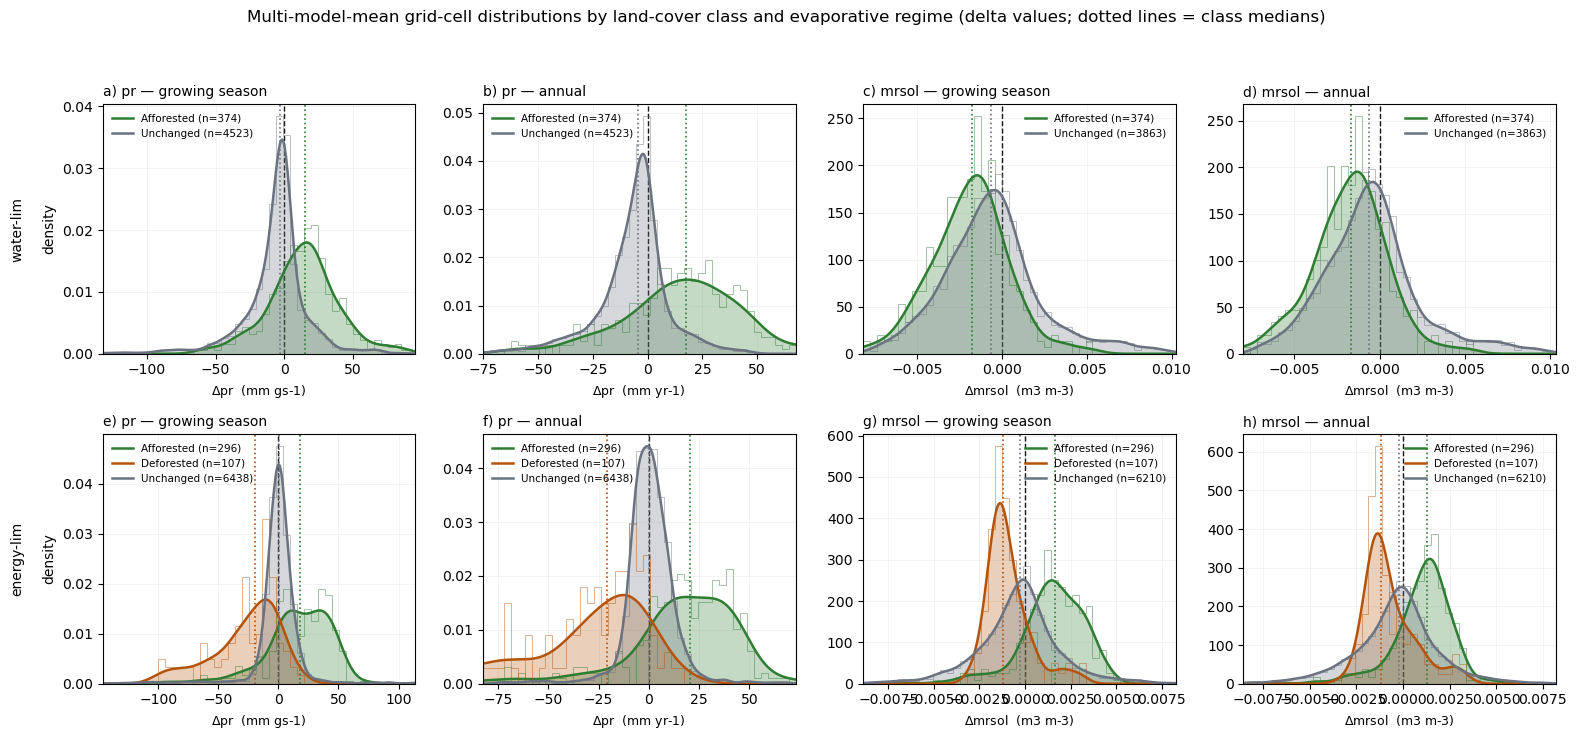

In [46]:
LC_COL = {"Afforested": "#2E7D32", "Deforested": "#B45309", "Unchanged": "#6B7280"}
PANEL = list("abcdefghijkl")


def _clip(x, q=0.005):
    lo, hi = np.quantile(x, [q, 1 - q])
    return x[(x >= lo) & (x <= hi)]


combos = [(v, s) for v in VARS for s in SEASONS]
fig, axes = plt.subplots(len(REGIMES), len(combos), figsize=(16, 7.5))
axes = np.atleast_2d(axes)

for i, r in enumerate(REGIMES):
    for j, (v, s) in enumerate(combos):
        ax = axes[i, j]
        F = fields[(v, s)].values
        pooled = np.concatenate([F[(cls.values == CLASSES.index((lc, r))) & np.isfinite(F)]
                                 for lc in LANDCOVER])
        if pooled.size == 0:
            continue
        lo, hi = np.quantile(pooled, [0.005, 0.995])
        grid = np.linspace(lo, hi, 400)

        for lc in LANDCOVER:
            x = F[(cls.values == CLASSES.index((lc, r))) & np.isfinite(F)]
            if x.size < MIN_CELLS:
                continue
            xc = _clip(x)
            ax.hist(xc, bins=45, range=(lo, hi), density=True, histtype="step",
                    color=LC_COL[lc], lw=0.7, alpha=0.45)
            try:
                kde = gaussian_kde(xc)
                ax.fill_between(grid, kde(grid), color=LC_COL[lc], alpha=0.28, lw=0)
                ax.plot(grid, kde(grid), color=LC_COL[lc], lw=1.8,
                        label=f"{lc} (n={x.size})")
            except Exception:
                pass
            ax.axvline(np.median(x), color=LC_COL[lc], lw=1.2, ls=":")

        ax.axvline(0, color="black", lw=1, ls="--", zorder=0)
        ax.set_xlim(lo, hi)
        ax.set_xlabel(f"{LABEL[VALUE_MODE]}{v}  ({UNIT[(v, VALUE_MODE, s)]})", fontsize=9)
        if j == 0:
            ax.set_ylabel(f"{r}\n\ndensity", fontsize=10)
        ax.set_title(f"{PANEL[i * len(combos) + j]}) {v} — "
                     f"{'growing season' if s == 'GS' else 'annual'}", fontsize=10, loc="left")
        ax.legend(fontsize=7.5, frameon=False)
        ax.grid(alpha=0.2, lw=0.5); ax.set_axisbelow(True)

fig.suptitle(f"Multi-model-mean grid-cell distributions by land-cover class and evaporative regime "
             f"({VALUE_MODE} values; dotted lines = class medians)", fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig(os.path.join(out_path, f"{FIG_PREFIX}kde_by_class.png"), dpi=400, bbox_inches="tight")
plt.show(); plt.close()

### 9a (companion). Distributions — Afforested vs Not Afforested, growing season only

Companion to 9a above, restricted to (i) the growing season only (no annual column) and (ii) a
binary land-cover contrast -- **Afforested** vs **Not Afforested** -- instead of the three-way
Afforested/Deforested/Unchanged split, so the comparison that matters for the paper's water-cycle
argument (does becoming forest change Pr/SM during the season the vegetation is actually active,
relative to land that did not become forest) is isolated in one place. `NOT_AFF_INCLUDES_DEFORESTED`
in the cell below controls what "Not Afforested" means: `False` (default) uses **Unchanged**
cells only, matching the `Afforested - Unchanged` contrast already used as the primary comparison
in the `st` table above; set it to `True` to instead pool Unchanged and Deforested cells into one
non-afforested baseline. The original 9a figure (three classes, GS+ANN) above is untouched.


Afforested-vs-Not-Afforested cell counts (growing season companion figures below):
  Afforested (water-lim)       n = 374
  Afforested (energy-lim)      n = 296
  Not Afforested (water-lim)   n = 4523
  Not Afforested (energy-lim)  n = 6438


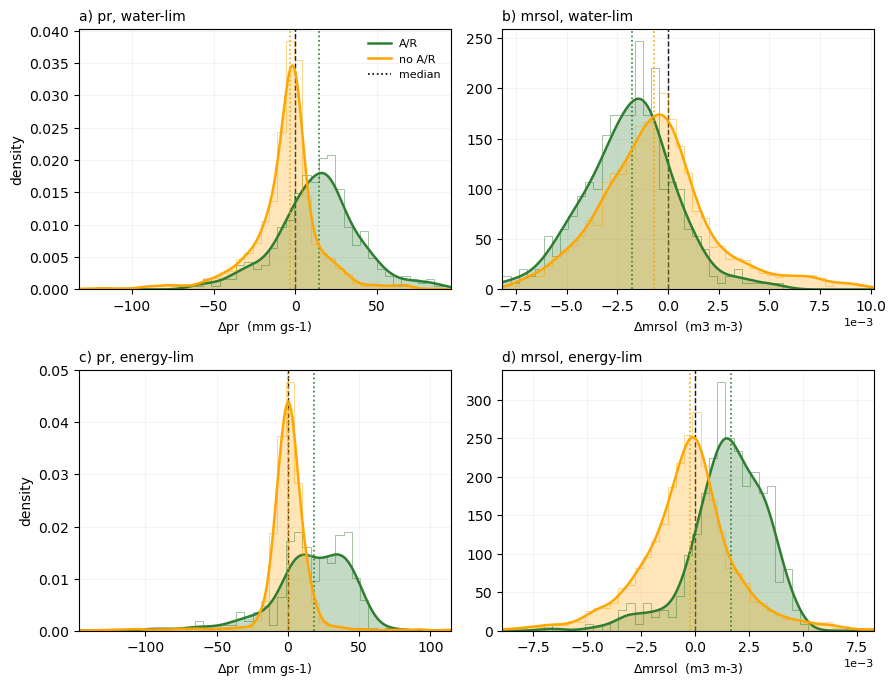

In [47]:
# --- Shared setup for the growing-season-only, Afforested-vs-Not-Afforested companion
# figures (9a/9b/9c below). Adds a second, coarser grouping (`cls2`) alongside the existing
# three-way `cls` -- does not modify `cls`, `fields`, `st`, or anything used by the original
# 9a/9b/9c/9d figures above.
NOT_AFF_INCLUDES_DEFORESTED = False   # False (default): "Not Afforested" = Unchanged cells only,
                                       # matching the existing "Afforested - Unchanged" contrast
                                       # in `st`/CONTRASTS above. True: pool Unchanged + Deforested
                                       # into one non-afforested baseline instead.

LC2 = ["Afforested", "Not Afforested"]
LC2_COL = {"Afforested": LC_COL["Afforested"], "Not Afforested": "orange" } #"#80776B"
CLASSES2 = [(lc, r) for lc in LC2 for r in REGIMES]
CLASS2_NAME = {i: f"{lc} ({r})" for i, (lc, r) in enumerate(CLASSES2)}
GS_COMBOS = [(v, "GS") for v in VARS]   # same variables as `combos`, growing season only

_aff_idx = LANDCOVER.index("Afforested")
_unch_idx = LANDCOVER.index("Unchanged")
_lc_code = cls // len(REGIMES)
_reg_code = cls % len(REGIMES)

_is_aff2 = (cls >= 0) & (_lc_code == _aff_idx)
_is_notaff2 = ((cls >= 0) & (_lc_code != _aff_idx) if NOT_AFF_INCLUDES_DEFORESTED
              else (cls >= 0) & (_lc_code == _unch_idx))

cls2 = xr.where(_is_aff2, _reg_code,
       xr.where(_is_notaff2, len(REGIMES) + _reg_code, -1)).astype(int)

print("Afforested-vs-Not-Afforested cell counts (growing season companion figures below):")
for i, (lc, r) in enumerate(CLASSES2):
    print(f"  {CLASS2_NAME[i]:28s} n = {int((cls2 == i).sum())}")


# --- 9a companion figure: KDE distributions, GS only, Afforested vs Not Afforested ---
fig, axes = plt.subplots(len(REGIMES), len(GS_COMBOS), figsize=(9, 7.5))
axes = np.atleast_2d(axes)

for i, r in enumerate(REGIMES):
    for j, (v, s) in enumerate(GS_COMBOS):
        ax = axes[i, j]
        F = fields[(v, s)].values
        pooled = np.concatenate([F[(cls2.values == CLASSES2.index((lc, r))) & np.isfinite(F)]
                                 for lc in LC2])
        if pooled.size == 0:
            continue
        lo, hi = np.quantile(pooled, [0.005, 0.995])
        grid = np.linspace(lo, hi, 400)

        for lc in LC2:
            x = F[(cls2.values == CLASSES2.index((lc, r))) & np.isfinite(F)]
            if x.size < MIN_CELLS:
                continue
            xc = _clip(x)
            ax.hist(xc, bins=45, range=(lo, hi), density=True, histtype="step",
                    color=LC2_COL[lc], lw=0.7, alpha=0.45)
            try:
                kde = gaussian_kde(xc)
                ax.fill_between(grid, kde(grid), color=LC2_COL[lc], alpha=0.28, lw=0)
                ax.plot(grid, kde(grid), color=LC2_COL[lc], lw=1.8, label=f"{lc} (n={x.size})")
            except Exception:
                pass
            ax.axvline(np.median(x), color=LC2_COL[lc], lw=1.2, ls=":")

        ax.axvline(0, color="black", lw=1, ls="--", zorder=0)
        ax.set_xlim(lo, hi)
        ax.set_xlabel(f"{LABEL[VALUE_MODE]}{v}  ({UNIT[(v, VALUE_MODE, s)]})", fontsize=9)
        if v == "mrsol":
            ax.ticklabel_format(axis="x", style="sci", scilimits=(-3, -3))
            ax.xaxis.get_offset_text().set_fontsize(8)
        if j == 0:
            ax.set_ylabel(f"density", fontsize=10)
        if i == 0 and j == 0:
            ax.set_title(f"a) {v}, water-lim", fontsize=10, loc="left")
        if i == 0 and j == 1:
            ax.set_title(f"b) {v}, water-lim", fontsize=10, loc="left")
        if i == 1 and j == 0:
            ax.set_title(f"c) {v}, energy-lim", fontsize=10, loc="left")
        if i == 1 and j == 1:
            ax.set_title(f"d) {v}, energy-lim", fontsize=10, loc="left")
        ax.grid(alpha=0.2, lw=0.5); ax.set_axisbelow(True)
        if (i == 0 and j == 0):
            legend_handles = [
                Line2D([], [], color=LC2_COL["Afforested"], lw=1.8, label="A/R"),
                Line2D([], [], color=LC2_COL["Not Afforested"], lw=1.8, label="no A/R"),
                Line2D([], [], color="black", lw=1.2, ls=":", label="median"),
            ]
            ax.legend(handles=legend_handles, fontsize=8, frameon=False)

# fig.suptitle("Growing-season distributions: Afforested vs Not Afforested, by evaporative regime",
            # fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig(os.path.join(out_path, f"{FIG_PREFIX}kde_by_class_gs_afforested_vs_not.png"),
           dpi=400, bbox_inches="tight")
plt.show(); plt.close()


### 9b. ECDFs

More honest than a histogram for a distributional comparison: no bandwidth or bin choice, and the
vertical gap between two curves *is* the quantity the Kolmogorov-Smirnov statistic measures, while
the horizontal gap is the Hodges-Lehmann shift. If the curves are nearly superimposed, no test on
any sample size should be allowed to call them different.

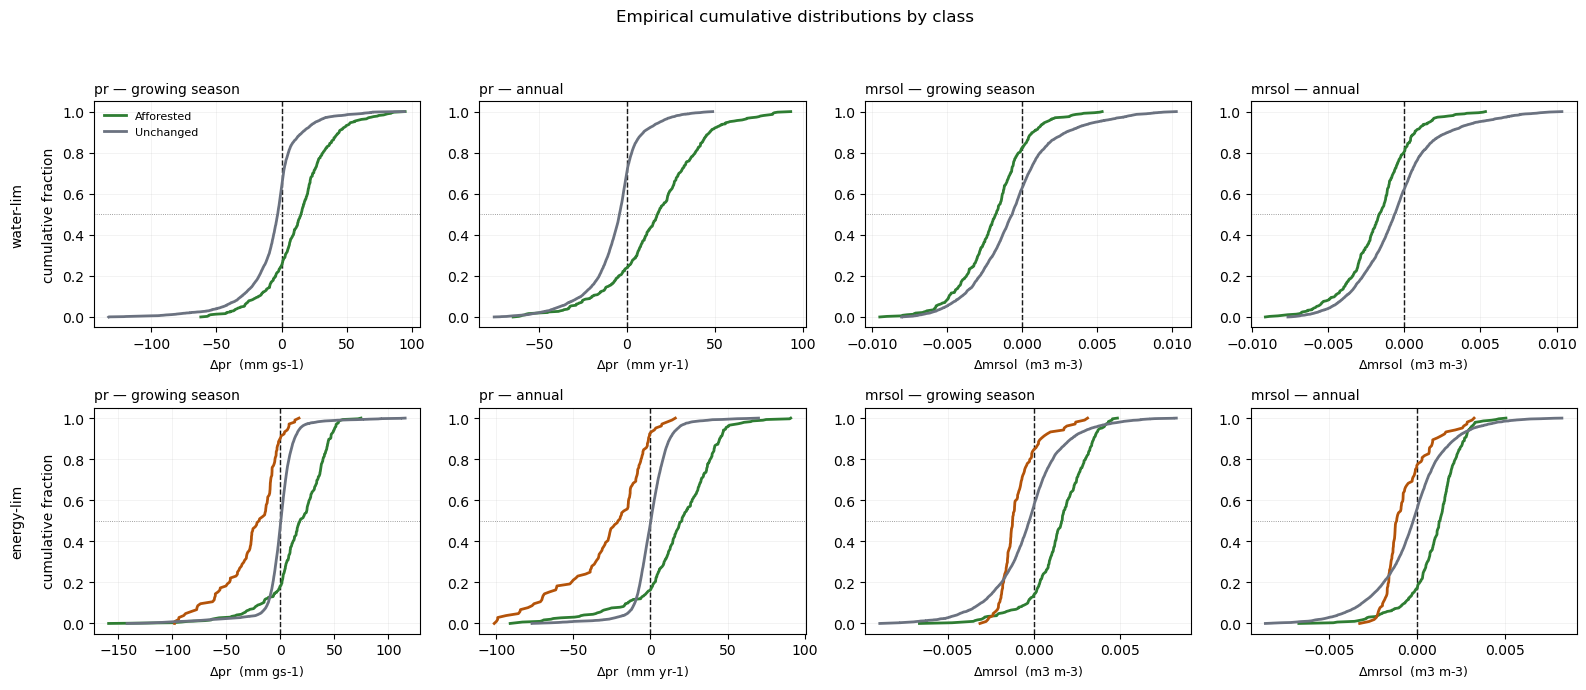

In [48]:
fig, axes = plt.subplots(len(REGIMES), len(combos), figsize=(16, 7))
axes = np.atleast_2d(axes)
for i, r in enumerate(REGIMES):
    for j, (v, s) in enumerate(combos):
        ax = axes[i, j]
        F = fields[(v, s)].values
        for lc in LANDCOVER:
            x = F[(cls.values == CLASSES.index((lc, r))) & np.isfinite(F)]
            if x.size < MIN_CELLS:
                continue
            xs = np.sort(_clip(x))
            ax.plot(xs, np.linspace(0, 1, xs.size), color=LC_COL[lc], lw=2, label=lc)
        ax.axvline(0, color="black", lw=1, ls="--", zorder=0)
        ax.axhline(0.5, color="grey", lw=0.6, ls=":", zorder=0)
        ax.set_xlabel(f"{LABEL[VALUE_MODE]}{v}  ({UNIT[(v, VALUE_MODE, s)]})", fontsize=9)
        if j == 0:
            ax.set_ylabel(f"{r}\n\ncumulative fraction", fontsize=10)
        ax.set_title(f"{v} — {'growing season' if s == 'GS' else 'annual'}", fontsize=10, loc="left")
        if i == 0 and j == 0:
            ax.legend(fontsize=8, frameon=False)
        ax.grid(alpha=0.2, lw=0.5); ax.set_axisbelow(True)
fig.suptitle("Empirical cumulative distributions by class", fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig(os.path.join(out_path, f"{FIG_PREFIX}ecdf_by_class.png"), dpi=400, bbox_inches="tight")
plt.show(); plt.close()

### 9b (companion). ECDFs — Afforested vs Not Afforested, growing season only

Same companion restriction as above (growing season only, `cls2`/`LC2` from the shared setup
cell above 9a), plotted as ECDFs. Original 9b (three classes, GS+ANN) above is untouched.


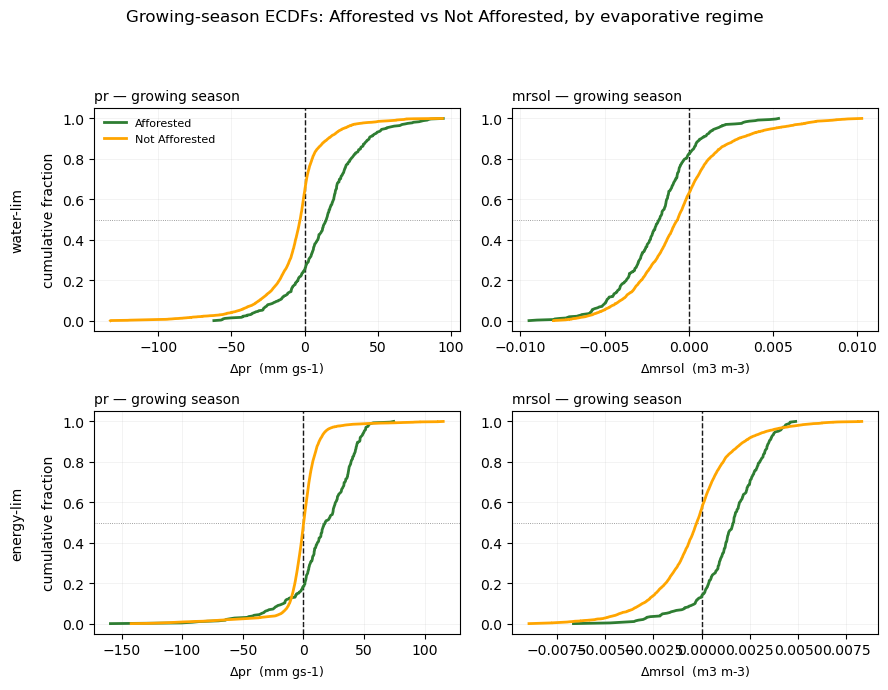

In [49]:
fig, axes = plt.subplots(len(REGIMES), len(GS_COMBOS), figsize=(9, 7))
axes = np.atleast_2d(axes)
for i, r in enumerate(REGIMES):
    for j, (v, s) in enumerate(GS_COMBOS):
        ax = axes[i, j]
        F = fields[(v, s)].values
        for lc in LC2:
            x = F[(cls2.values == CLASSES2.index((lc, r))) & np.isfinite(F)]
            if x.size < MIN_CELLS:
                continue
            xs = np.sort(_clip(x))
            ax.plot(xs, np.linspace(0, 1, xs.size), color=LC2_COL[lc], lw=2, label=lc)
        ax.axvline(0, color="black", lw=1, ls="--", zorder=0)
        ax.axhline(0.5, color="grey", lw=0.6, ls=":", zorder=0)
        ax.set_xlabel(f"{LABEL[VALUE_MODE]}{v}  ({UNIT[(v, VALUE_MODE, s)]})", fontsize=9)
        if j == 0:
            ax.set_ylabel(f"{r}\n\ncumulative fraction", fontsize=10)
        ax.set_title(f"{v} — growing season", fontsize=10, loc="left")
        if i == 0 and j == 0:
            ax.legend(fontsize=8, frameon=False)
        ax.grid(alpha=0.2, lw=0.5); ax.set_axisbelow(True)
fig.suptitle("Growing-season ECDFs: Afforested vs Not Afforested, by evaporative regime",
            fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig(os.path.join(out_path, f"{FIG_PREFIX}ecdf_by_class_gs_afforested_vs_not.png"),
           dpi=400, bbox_inches="tight")
plt.show(); plt.close()


### 9c. Effect size with block-bootstrap CI

Each diamond is the observed Cliff's delta; the grey bar behind it is the 95 % block-bootstrap CI
(resampling `BLOCK_DEG` spatial tiles within the actual, fixed class geometry -- see the Section-2
intro cell and the `block_bootstrap_delta` docstring for the calibration caveat, since there is no
spatial-shift null here to fall back on). A bar that crosses zero is not distinguishable from no
effect at this resampling precision. The light shading marks the "negligible effect" range
`|d| < 0.147`, so a result must clear both -- CI excludes zero, and delta outside the negligible
band -- to be worth a claim.

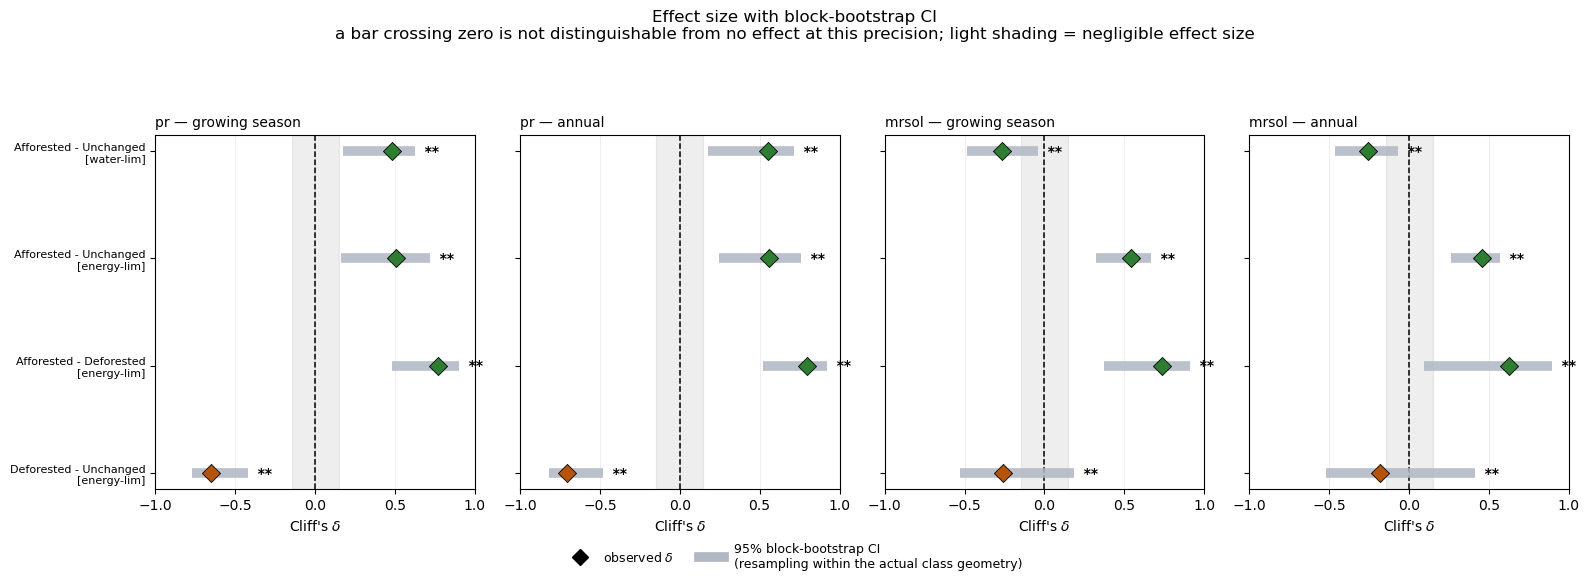

In [50]:
fig, axes = plt.subplots(1, len(combos), figsize=(16, 5.5), sharey=True)
axes = np.atleast_1d(axes)
for j, (v, s) in enumerate(combos):
    ax = axes[j]
    sub = st[(st.variable == v) & (st.season == s)].copy()
    sub["lab"] = sub.contrast + "\n[" + sub.regime + "]"
    sub = sub.iloc[::-1]
    y = np.arange(len(sub))

    ax.axvspan(-0.147, 0.147, color="grey", alpha=0.13, zorder=0)
    ax.axvline(0, color="black", lw=1.1, ls="--", zorder=1)

    for yi, (_, rr) in enumerate(sub.iterrows()):
        # block-bootstrap 95% CI on Cliff's delta, resampling within the actual class geometry
        if np.isfinite(rr.delta_ci_lo):
            ax.plot([rr.delta_ci_lo, rr.delta_ci_hi], [yi, yi], lw=7, solid_capstyle="butt",
                    color="#B0B7C3", alpha=0.85, zorder=2)
        ax.scatter(rr.cliffs_delta, yi, s=85, zorder=4, marker="D",
                   color=LC_COL[rr.contrast.split(" - ")[0]], edgecolor="black", linewidth=0.6)
        if rr.p_mwu_fdr < 0.05:
            ax.text(max(rr.cliffs_delta, rr.delta_ci_hi), yi, "  " + rr.signif, va="center",
                    fontsize=10, fontweight="bold")

    ax.set_yticks(y); ax.set_yticklabels(sub.lab, fontsize=8)
    ax.set_xlabel("Cliff's $\\delta$", fontsize=10)
    ax.set_xlim(-1, 1)
    ax.set_title(f"{v} — {'growing season' if s == 'GS' else 'annual'}", fontsize=10, loc="left")
    ax.grid(axis="x", alpha=0.25, lw=0.6); ax.set_axisbelow(True)

handles = [Line2D([], [], marker="D", ls="", color="k", markersize=8, label="observed $\\delta$"),
           Line2D([], [], lw=7, color="#B0B7C3", label="95% block-bootstrap CI\n"
                                                       "(resampling within the actual class geometry)")]
fig.legend(handles=handles, loc="lower center", ncol=2, frameon=False, fontsize=9,
           bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Effect size with block-bootstrap CI\n"
             "a bar crossing zero is not distinguishable from no effect at this precision; "
             "light shading = negligible effect size",
             fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.90])
fig.savefig(os.path.join(out_path, f"{FIG_PREFIX}effect_sizes.png"), dpi=400, bbox_inches="tight")
plt.show(); plt.close()

### 9c (companion, new). Effect size with CI — Afforested vs Not Afforested, growing season only

The comparison asked for directly: Cliff's delta (with 95% block-bootstrap CI) for the
**Afforested vs Not Afforested** contrast, computed separately for water-limited and
energy-limited cells, restricted to the growing season. Reuses `cliffs_delta`,
`hodges_lehmann`, `block_bootstrap_delta` and `decorrelation_cells` from the Statistics section
above unchanged -- only the class grouping (`cls2`/`CLASSES2` from the shared setup cell above
9a) and season (GS only, no annual column) differ from the `st` table. Original 9c (three-class
contrasts, GS+ANN) above is untouched.


,variable,regime,n_a,n_b,hl_shift,unit,cliffs_delta,delta_size,delta_ci_lo,delta_ci_hi,ci_excludes_zero,p_mwu_fdr,signif
0,pr,water-lim,374,4523,18.89,mm gs-1,0.4805,large,0.1565,0.6232,True,1.18e-53,**
1,pr,energy-lim,296,6438,18.8,mm gs-1,0.5086,large,0.1778,0.7282,True,1.516e-49,**
2,mrsol,water-lim,374,3863,-0.001163,m3 m-3,-0.2683,small,-0.4764,-0.05997,True,9.554e-18,**
3,mrsol,energy-lim,296,6210,0.001935,m3 m-3,0.5423,large,0.3244,0.6731,True,0,**


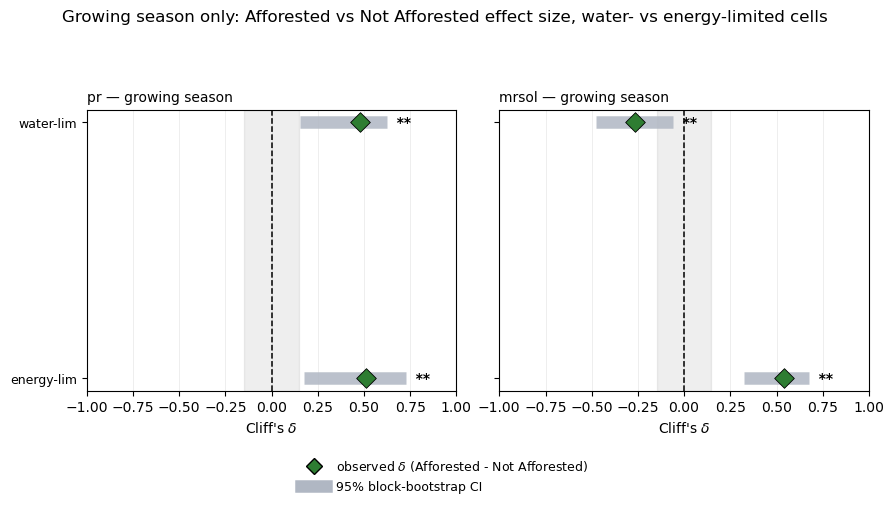

In [51]:
_rows2 = []
for v in VARS:
    s = "GS"
    F = fields[(v, s)]
    Lx, Ly = decorrelation_cells(F)
    for r in REGIMES:
        ia = CLASSES2.index(("Afforested", r)); ib = CLASSES2.index(("Not Afforested", r))
        xa = F.values[(cls2.values == ia) & np.isfinite(F.values)]
        xb = F.values[(cls2.values == ib) & np.isfinite(F.values)]
        if len(xa) < MIN_CELLS or len(xb) < MIN_CELLS:
            continue

        d, p_raw = cliffs_delta(xa, xb)
        hl = hodges_lehmann(xa, xb, rng=rng)
        p_ks = ks_2samp(xa, xb).pvalue
        lo, hi = block_bootstrap_delta(F.values, cls2.values, lat2d.values, lon2d.values,
                                       ia, ib, rng=rng)
        n_eff_a = max(len(xa) / (Lx * Ly), 2)
        n_eff_b = max(len(xb) / (Lx * Ly), 2)

        _rows2.append(dict(
            variable=v, season=s, regime=r, contrast="Afforested - Not Afforested",
            unit=UNIT[(v, VALUE_MODE, s)],
            n_a=len(xa), n_b=len(xb),
            median_a=float(np.median(xa)), median_b=float(np.median(xb)),
            hl_shift=hl, cliffs_delta=d, delta_size=interpret_delta(d),
            delta_ci_lo=lo, delta_ci_hi=hi,
            p_mwu_raw=p_raw, p_ks_raw=p_ks,
            n_eff_a=n_eff_a, n_eff_b=n_eff_b, decorr_cells=f"{Lx}x{Ly}",
        ))

st2 = pd.DataFrame(_rows2)
st2["p_mwu_fdr"] = multipletests(st2["p_mwu_raw"].fillna(1.0), alpha=0.05, method="fdr_bh")[1]
st2["signif"] = np.where(st2.p_mwu_fdr < 0.01, "**", np.where(st2.p_mwu_fdr < 0.05, "*", "n.s."))
st2["ci_excludes_zero"] = (st2.delta_ci_lo > 0) | (st2.delta_ci_hi < 0)

pd.set_option("display.width", 250, "display.max_rows", 200)
display(st2[["variable", "regime", "n_a", "n_b", "hl_shift", "unit", "cliffs_delta", "delta_size",
             "delta_ci_lo", "delta_ci_hi", "ci_excludes_zero", "p_mwu_fdr", "signif"]])

st2.to_csv(os.path.join(out_path, f"{FIG_PREFIX}gs_afforested_vs_not_stats.csv"), index=False)

# --- 9c (new) figure: effect size with block-bootstrap CI, Afforested vs Not Afforested, GS only
fig, axes = plt.subplots(1, len(VARS), figsize=(9, 4.5), sharey=True)
axes = np.atleast_1d(axes)
for j, v in enumerate(VARS):
    ax = axes[j]
    sub = st2[st2.variable == v].copy()
    sub["lab"] = sub.regime
    sub = sub.iloc[::-1]
    y = np.arange(len(sub))

    ax.axvspan(-0.147, 0.147, color="grey", alpha=0.13, zorder=0)
    ax.axvline(0, color="black", lw=1.1, ls="--", zorder=1)

    for yi, (_, rr) in enumerate(sub.iterrows()):
        if np.isfinite(rr.delta_ci_lo):
            ax.plot([rr.delta_ci_lo, rr.delta_ci_hi], [yi, yi], lw=9, solid_capstyle="butt",
                    color="#B0B7C3", alpha=0.85, zorder=2)
        ax.scatter(rr.cliffs_delta, yi, s=100, zorder=4, marker="D",
                   color=LC2_COL["Afforested"], edgecolor="black", linewidth=0.6)
        if rr.p_mwu_fdr < 0.05:
            ax.text(max(rr.cliffs_delta, rr.delta_ci_hi), yi, "  " + rr.signif, va="center",
                    fontsize=10, fontweight="bold")

    ax.set_yticks(y); ax.set_yticklabels(sub.lab, fontsize=9)
    ax.set_xlabel("Cliff's $\\delta$", fontsize=10)
    ax.set_xlim(-1, 1)
    ax.set_title(f"{v} — growing season", fontsize=10, loc="left")
    ax.grid(axis="x", alpha=0.25, lw=0.6); ax.set_axisbelow(True)

handles = [Line2D([], [], marker="D", ls="", color=LC2_COL["Afforested"], markeredgecolor="black",
                  markersize=8, label="observed $\\delta$ (Afforested - Not Afforested)"),
           Line2D([], [], lw=9, color="#B0B7C3", label="95% block-bootstrap CI")]
fig.legend(handles=handles, loc="lower center", ncol=1, frameon=False, fontsize=9,
           bbox_to_anchor=(0.5, -0.12))
fig.suptitle("Growing season only: Afforested vs Not Afforested effect size, "
             "water- vs energy-limited cells", fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.90])
fig.savefig(os.path.join(out_path, f"{FIG_PREFIX}effect_sizes_gs_afforested_vs_not.png"),
           dpi=400, bbox_inches="tight")
plt.show(); plt.close()


### 9c (reconciliation). Class contrast (HL) vs. root-zone budget (m$^3$ Mha$^{-1}$), A/R cells

Puts the growing-season class contrast of 9c and the Section-1 root-zone budget on one table.
`HL_GS` is relative to not-afforested cells; the `med_*` columns are the medians of each class on
its own; `budget_*` is the absolute m$^3$ per Mha converted (annual mean, 0-2 m). `budget_MMMfield`
applies the Section-1 formula to the same multi-model-mean 1$^\circ$ field and cells used here, so
it differs from `budget_perModel` only through aggregation (ensemble mean first vs. per model
first); `dTree` is in %. Needs Section 1 run in the same kernel.


In [52]:
assert VALUE_MODE == "delta", "reconciliation assumes VALUE_MODE == 'delta'"
_K = ROOT_ZONE_DEPTH_M * 100 * M2_PER_MHA          # (m3 m-3 per % treeFrac) -> m3 Mha-1  (= 2e12)

_rec = []
for r in REGIMES:
    sel = (cls2 == CLASSES2.index(("Afforested", r)))
    selb = (cls2 == CLASSES2.index(("Not Afforested", r)))
    Fgs, Fann = fields[("mrsol", "GS")], fields[("mrsol", "ANN")]
    ok = sel & Fann.notnull()
    num = float((Fann.where(ok) * ROOT_ZONE_DEPTH_M * aw).sum(skipna=True))
    den = float(((dtree_mmm / 100) * aw / M2_PER_MHA).where(ok).sum(skipna=True))
    hl = st2[(st2.variable == "mrsol") & (st2.regime == r)].hl_shift
    per_model = np.asarray(results_water_permha[f"Afforested\n({r})"], dtype=float)
    _rec.append({
        "regime": r,
        "n_AR": int(sel.sum()),
        "dTree_%": float(dtree_mmm.where(sel).weighted(aw).mean(skipna=True)),
        "HL_GS_e-3": 1e3 * float(hl.iloc[0]) if len(hl) else np.nan,
        "med_AR_GS_e-3": 1e3 * float(Fgs.where(sel).median()),
        "med_noAR_GS_e-3": 1e3 * float(Fgs.where(selb).median()),
        "med_AR_ANN_e-3": 1e3 * float(Fann.where(sel).median()),
        "budget_MMMfield_e8": num / den / 1e8,
        "budget_perModel_e8": np.nanmean(per_model) / 1e8,
        "budget_perModel_sd_e8": np.nanstd(per_model) / 1e8,
        "models_neg": f"{int((per_model < 0).sum())}/{int(np.isfinite(per_model).sum())}",
    })

rec = pd.DataFrame(_rec)
with pd.option_context("display.width", 250, "display.float_format", "{:.3g}".format):
    display(rec)
print("SM columns in 1e-3 m3 m-3; budget columns in 1e8 m3 Mha-1; dTree in %.")
print("HL_GS ~ med_AR_GS - med_noAR_GS only if both classes have similar shape.")
print("budget_MMMfield vs budget_perModel: a gap (or sign change) = aggregation / inter-model sign spread.")


,regime,n_AR,dTree_%,HL_GS_e-3,med_AR_GS_e-3,med_noAR_GS_e-3,med_AR_ANN_e-3,budget_MMMfield_e8,budget_perModel_e8,budget_perModel_sd_e8,models_neg
0,water-lim,374,22.5,-1.16,-1.76,-0.661,-1.66,-1.59,-1.55,2.48,5/7
1,energy-lim,296,23.8,1.93,1.64,-0.257,1.28,0.84,-0.478,1.22,4/7


SM columns in 1e-3 m3 m-3; budget columns in 1e8 m3 Mha-1; dTree in %.
HL_GS ~ med_AR_GS - med_noAR_GS only if both classes have similar shape.
budget_MMMfield vs budget_perModel: a gap (or sign change) = aggregation / inter-model sign spread.


### 9d. Where the classes are

Always show this alongside the distributions. It is the figure that lets a reader judge the
confounding for themselves: if the afforested and unchanged classes occupy visibly different
climate zones, any difference between their distributions is partly geography.

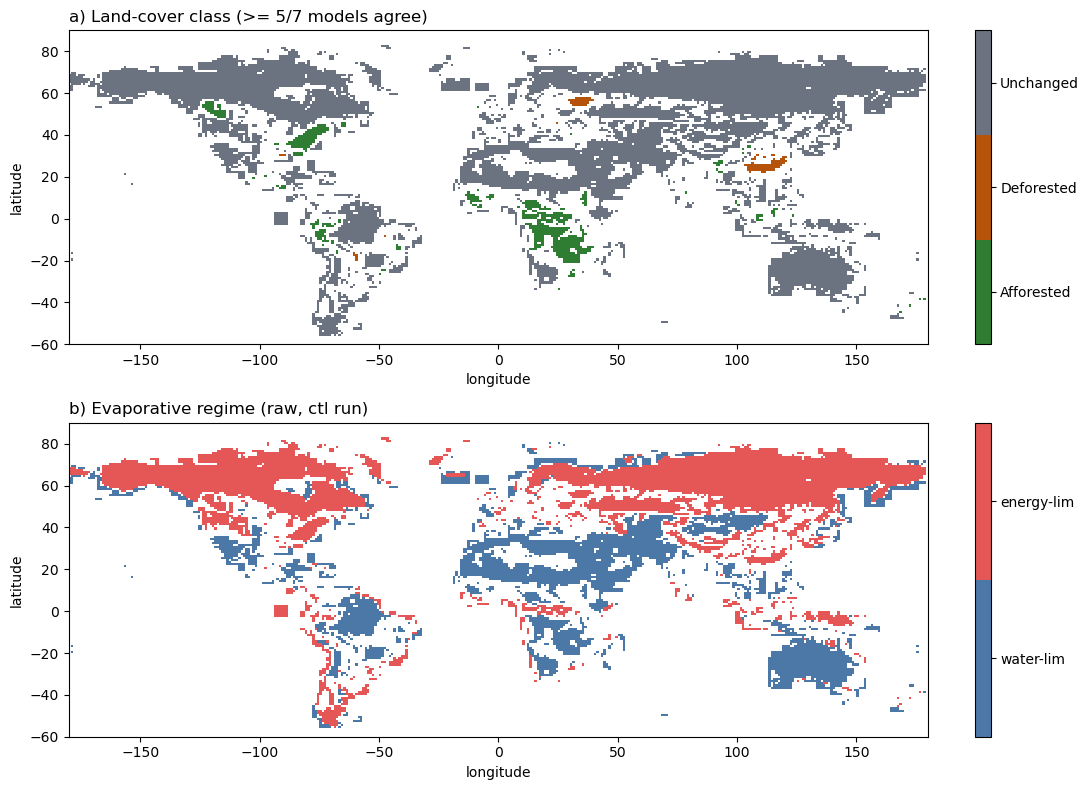

In [171]:
import matplotlib.colors as mcolors

fig, axes = plt.subplots(2, 1, figsize=(11, 8))
cmap = mcolors.ListedColormap([LC_COL[lc] for lc in LANDCOVER])
lc_show = xr.where(cls >= 0, cls // len(REGIMES), np.nan)
reg_show = xr.where(cls >= 0, cls % len(REGIMES), np.nan)

im0 = axes[0].pcolormesh(lc_show.lon, lc_show.lat, lc_show, cmap=cmap, vmin=-0.5,
                         vmax=len(LANDCOVER) - 0.5, shading="auto")
cb0 = fig.colorbar(im0, ax=axes[0], ticks=range(len(LANDCOVER)), fraction=0.03)
cb0.ax.set_yticklabels(LANDCOVER)
axes[0].set_title("a) Land-cover class (>= %d/%d models agree)"
                  % (round(AGREE_FRAC * len(models)), len(models)), loc="left")

im1 = axes[1].pcolormesh(reg_show.lon, reg_show.lat, reg_show,
                         cmap=mcolors.ListedColormap(["#4C78A8", "#E45756"]),
                         vmin=-0.5, vmax=1.5, shading="auto")
cb1 = fig.colorbar(im1, ax=axes[1], ticks=[0, 1], fraction=0.03)
cb1.ax.set_yticklabels(REGIMES)
axes[1].set_title("b) Evaporative regime (%s, %s run)" % (REGIME_METHOD, REGIME_REFERENCE),
                  loc="left")

for ax in axes:
    ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
    ax.set_xlim(-180, 180); ax.set_ylim(*LAT_RANGE)
fig.tight_layout()
fig.savefig(os.path.join(out_path, f"{FIG_PREFIX}class_maps.png"), dpi=400, bbox_inches="tight")
plt.show(); plt.close()

## 10. Interpretation guide

Read the output with this decision tree, in order. Do not skip to the p-value.

In [172]:
print("=" * 96)
print("INTERPRETATION".center(96))
print("=" * 96)

for _, r in st.iterrows():
    tag = f"{r.variable} | {r.season} | {r.regime} | {r.contrast}"
    ci_excl = bool(r.ci_excludes_zero)
    negligible = abs(r.cliffs_delta) < 0.147
    p_ok = r.p_mwu_fdr < 0.05

    if negligible and not ci_excl:
        verdict = "NULL — effect negligible and the block-bootstrap CI includes zero"
    elif negligible and ci_excl:
        verdict = ("DETECTABLE BUT TRIVIAL — CI excludes zero, effect size negligible; "
                   "quote the effect size, not the CI/p-value")
    elif not negligible and ci_excl and p_ok:
        verdict = "SUPPORTED — non-trivial effect size, CI excludes zero, FDR-corrected p < 0.05"
    elif not negligible and not ci_excl:
        verdict = ("SUGGESTIVE ONLY — effect size non-trivial but the block-bootstrap CI still "
                   "includes zero at this resampling precision")
    else:
        verdict = "MIXED — see effect size, CI, and p-value"

    print(f"\n{tag}")
    print(f"   Cliff's d = {r.cliffs_delta:+.3f} ({r.delta_size});  "
          f"HL shift = {r.hl_shift:+.4g} {r.unit}")
    print(f"   block-bootstrap 95% CI = [{r.delta_ci_lo:+.3f}, {r.delta_ci_hi:+.3f}]  "
          f"-> {'excludes' if ci_excl else 'includes'} zero")
    print(f"   p_mwu(FDR) = {r.p_mwu_fdr:.3g}   |   raw Mann-Whitney p = {r.p_mwu_raw:.3g} "
          f"<- both inflated by ~{r.n_a / r.n_eff_a:.0f}x oversampling (grid cells are not "
          f"independent -- see Section-2 intro)")
    print(f"   -> {verdict}")

print("\n" + "=" * 96)
n_sup = int(((st.p_mwu_fdr < 0.05) & (st.cliffs_delta.abs() >= 0.147) & st.ci_excludes_zero).sum())
print(f"{n_sup} of {len(st)} contrasts are SUPPORTED on all three criteria.")
if n_sup == 0:
    print("""
None survive. Before treating that as a failure, note what it means: at these actual, IAM-
prescribed afforestation locations, the CMIP6 LUMIP ensemble does not place afforested land in a
detectably different Pr/SM regime from unchanged land at this forcing level, once the precision
of the effect-size estimate is accounted for. Combined with the ensemble-level null from
`water_avail_bootstrap.ipynb`, that is a coherent, defensible and publishable result -- and it is
the same conclusion from two methodologically independent directions, which is a stronger paper
than a marginal positive from either one alone.""")

                                         INTERPRETATION                                         

pr | GS | water-lim | Afforested - Unchanged
   Cliff's d = +0.480 (large);  HL shift = +18.84 mm gs-1
   block-bootstrap 95% CI = [+0.175, +0.625]  -> excludes zero
   p_mwu(FDR) = 2.36e-53   |   raw Mann-Whitney p = 5.9e-54 <- both inflated by ~24x oversampling (grid cells are not independent -- see Section-2 intro)
   -> SUPPORTED — non-trivial effect size, CI excludes zero, FDR-corrected p < 0.05

pr | GS | energy-lim | Afforested - Unchanged
   Cliff's d = +0.509 (large);  HL shift = +19.02 mm gs-1
   block-bootstrap 95% CI = [+0.164, +0.721]  -> excludes zero
   p_mwu(FDR) = 3.64e-49   |   raw Mann-Whitney p = 1.14e-49 <- both inflated by ~24x oversampling (grid cells are not independent -- see Section-2 intro)
   -> SUPPORTED — non-trivial effect size, CI excludes zero, FDR-corrected p < 0.05

pr | GS | energy-lim | Afforested - Deforested
   Cliff's d = +0.767 (large);  HL shift = 

## 11. Methods text

> **Distributional analysis.** Each model's 2071-2100 mean fields were computed on its native grid
> and then regridded conservatively onto a common 1° x 1° grid; the categorical evaporative-regime
> field was regridded by nearest neighbour. Grid cells were assigned to a land-cover class
> (afforested, deforested, unchanged) and an evaporative regime only where at least five of the
> seven models agreed on the assignment individually, so that the strata are properties of the
> ensemble rather than of any single model. Distributions of the multi-model-mean afforestation
> anomaly (`ssp126Lu - ssp370`) were then compared between classes within each regime, at the
> grid-cell locations where the scenario's land-use trajectory actually places each class; we do
> not test against a spatially-randomized placement of afforestation, since afforestation location
> in these simulations is prescribed by the integrated assessment model and was never a candidate
> for a different longitude.
>
> Because grid cells are strongly spatially autocorrelated -- and regridding increases that
> autocorrelation -- conventional rank tests over grid cells are severely anti-conservative here;
> the effective sample size, estimated from the e-folding decorrelation length of each field, is
> smaller than the cell count by a factor of [FILL FROM TABLE]. We therefore report Cliff's delta
> as a sample-size-independent effect size, together with the Hodges-Lehmann shift in physical
> units, and a block-bootstrap confidence interval (resampling spatial tiles within each class,
> 2000 resamples) as a precision indicator that still accounts for spatial autocorrelation of the
> actual, fixed class geometry. In a calibration on synthetic fields with matched correlation
> structure and class clustering, this interval excluded zero under a true null in [FILL FROM
> TABLE, ~22-33 %] of replicates at a nominal 5 %, against 92 % for a Mann-Whitney test and 100 %
> for a Kolmogorov-Smirnov test over the same grid cells -- so "CI excludes zero" is reported as
> suggestive evidence, not a calibrated significance test. Uncorrected and Benjamini-Hochberg
> FDR-corrected Mann-Whitney and Kolmogorov-Smirnov p-values are reported for transparency and
> are not used to support any conclusion on their own.